# Dataset audit

Check the raw dataset inventory and inspect representative file structure before preprocessing.

In [10]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import json
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nLibraries imported successfully.")

Python version: 3.13.7
Pandas version: 3.0.0
NumPy version: 2.3.5

Libraries imported successfully.


## 1. Locate the Project Root

This section locates the repository folder containing the raw keystroke logs.

The notebook first searches the current working directory and its parent directories. It then checks the configured Windows project path as a fallback.

Expected location:

`C:\ML project\PARKINSONS-DISEASE-PREDICTOR`

In [11]:
def find_project_root(start_path):
    """
    Search the current directory and its parents for the project root.
    """
    start_path = Path(start_path).resolve()
    candidates = [start_path, *start_path.parents]

    for candidate in candidates:
        expected_log_dir = (
            candidate / "data" / "raw" / "keystroke_logs"
        )

        if expected_log_dir.is_dir():
            return candidate

    return None


PROJECT_ROOT = find_project_root(Path.cwd())

# Fallback for the project's current Windows location.
if PROJECT_ROOT is None:
    manual_root = Path(
        r"C:\ML project\PARKINSONS-DISEASE-PREDICTOR"
    )

    if (
        manual_root / "data" / "raw" / "keystroke_logs"
    ).is_dir():
        PROJECT_ROOT = manual_root


if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be located.\n"
        "Open Jupyter from the project directory or update "
        "the manual_root path in this cell."
    )


DATA_ROOT = PROJECT_ROOT / "data" / "raw"

LOG_DIR = DATA_ROOT / "keystroke_logs"

METADATA_DIR = DATA_ROOT / "participant_metadata"

REPORT_DIR = PROJECT_ROOT / "reports" / "local_audit"


print("Project root:", PROJECT_ROOT)
print("Keystroke logs:", LOG_DIR)
print("Participant metadata:", METADATA_DIR)
print("Audit reports:", REPORT_DIR)


if not LOG_DIR.is_dir():
    raise FileNotFoundError(
        f"Keystroke log directory not found: {LOG_DIR}"
    )

if not METADATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Metadata directory not found: {METADATA_DIR}\n"
        "Extract the participant metadata text files into "
        "data/raw/participant_metadata/."
    )

print("\nProject directories verified successfully.")

Project root: C:\ML project\PARKINSONS-DISEASE-PREDICTOR
Keystroke logs: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\data\raw\keystroke_logs
Participant metadata: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\data\raw\participant_metadata
Audit reports: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit

Project directories verified successfully.


## 2. Identify Dataset Files

The monthly log filenames are expected to follow this format:

`PARTICIPANTID_YYMM.txt`

The participant metadata filenames are expected to follow:

`User_PARTICIPANTID.txt`

Only files matching these patterns are included. Other files, including ZIP archives, are ignored.

In [12]:
LOG_FILENAME_RE = re.compile(
    r"^(?P<participant_id>[A-Za-z0-9]+)_(?P<year_month>\d{4})\.txt$",
    re.IGNORECASE
)

METADATA_FILENAME_RE = re.compile(
    r"^User_(?P<participant_id>[A-Za-z0-9]+)\.txt$",
    re.IGNORECASE
)


log_files = sorted(
    path
    for path in LOG_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() == ".txt"
    and LOG_FILENAME_RE.match(path.name)
)

metadata_files = sorted(
    path
    for path in METADATA_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() == ".txt"
    and METADATA_FILENAME_RE.match(path.name)
)


print("Monthly log files:", f"{len(log_files):,}")
print("Participant metadata files:", f"{len(metadata_files):,}")


if not log_files:
    raise FileNotFoundError(
        f"No valid monthly log files were found in {LOG_DIR}."
    )

if not metadata_files:
    raise FileNotFoundError(
        f"No valid participant metadata files were found "
        f"in {METADATA_DIR}."
    )

print("\nFile discovery completed successfully.")

Monthly log files: 2,165
Participant metadata files: 646

File discovery completed successfully.


## 3. Create the Monthly Log Manifest

A manifest summarizes the raw files without loading all keystroke events into memory.

It records:
- Filename
- Participant identifier
- Month identifier
- File size
- Whether the file is empty

This helps us understand the coverage and structure of the dataset.

In [13]:
manifest_rows = []

for path in log_files:
    match = LOG_FILENAME_RE.match(path.name)

    manifest_rows.append({
        "filename": path.name,
        "participant_id": match.group(
            "participant_id"
        ).upper(),
        "year_month": match.group("year_month"),
        "size_bytes": path.stat().st_size,
        "empty_file": path.stat().st_size == 0,
    })


log_manifest = pd.DataFrame(manifest_rows)


print("Total monthly files:", len(log_manifest))

print(
    "Unique participants:",
    log_manifest["participant_id"].nunique()
)

print(
    "Distinct year-month values:",
    log_manifest["year_month"].nunique()
)

print(
    "Empty files:",
    int(log_manifest["empty_file"].sum())
)


print("\nManifest preview:")
display(log_manifest.head(10))


files_per_participant = (
    log_manifest
    .groupby("participant_id")
    .size()
    .rename("monthly_log_files")
    .reset_index()
    .sort_values(
        "monthly_log_files",
        ascending=False
    )
)


print("\nParticipants with the most monthly files:")
display(files_per_participant.head(10))


print("\nNumber of files per month:")
display(
    log_manifest["year_month"]
    .value_counts()
    .sort_index()
    .rename_axis("year_month")
    .to_frame("number_of_files")
)

Total monthly files: 2165
Unique participants: 754
Distinct year-month values: 20
Empty files: 5

Manifest preview:


,filename,participant_id,year_month,size_bytes,empty_file
0,04AUPVMQXY_1708.txt,04AUPVMQXY,1708,3717,False
1,0EA27ICBLF_1607.txt,0EA27ICBLF,1607,8415612,False
2,0EA27ICBLF_1608.txt,0EA27ICBLF,1608,933401,False
3,0JIWJUQ4ZN_1703.txt,0JIWJUQ4ZN,1703,9204,False
4,0M2T2Q0WQF_1704.txt,0M2T2Q0WQF,1704,1652,False
5,0NMZ9JBBHI_1608.txt,0NMZ9JBBHI,1608,51743,False
6,0NMZ9JBBHI_1609.txt,0NMZ9JBBHI,1609,290221,False
7,0NMZ9JBBHI_1610.txt,0NMZ9JBBHI,1610,26790,False
8,0NPYYFR8TU_1710.txt,0NPYYFR8TU,1710,12626,False
9,0NPYYFR8TU_1711.txt,0NPYYFR8TU,1711,25665,False



Participants with the most monthly files:


,participant_id,monthly_log_files
699,XWAX2IHF3O,19
457,NPACI6EW26,19
400,LA6KW35OXK,19
81,6WBXSDG5BB,18
322,IDYIDJBAXF,18
98,8EY6NZAKCI,17
132,AFQWSP8ARK,17
284,GRPUBQLE4F,16
105,927ZLCPEJM,15
519,QAH9IVALVC,15



Number of files per month:


,number_of_files
year_month,
1605,1
1606,12
1607,35
1608,85
1609,99
1610,62
1611,44
1612,39
1701,66


## 4. Parse Participant Metadata

Each participant metadata file contains fields such as:

- `Parkinsons`
- `Gender`
- `BirthYear`
- `Tremors`
- `DiagnosisYear`
- `UPDRS`
- `Impact`
- Medication-related fields

For this research project, `Parkinsons` is the target label.

The other clinical fields will be audited but will not be used as initial typing-based predictors.

In [14]:
def normalize_field_name(name):
    """
    Normalize field names into lowercase snake_case.
    Example: 'MAOB ' becomes 'maob'.
    """
    normalized = re.sub(
        r"[^a-z0-9]+",
        "_",
        name.strip().lower()
    )

    return normalized.strip("_")


def parse_bool(value):
    """
    Convert common text representations into Boolean values.
    Missing or unrecognized values become pandas.NA.
    """
    if value is None or pd.isna(value):
        return pd.NA

    value = str(value).strip().lower()

    if value in {"true", "1", "yes", "y"}:
        return True

    if value in {"false", "0", "no", "n"}:
        return False

    return pd.NA


metadata_rows = []
metadata_parse_issues = []


for path in metadata_files:

    match = METADATA_FILENAME_RE.match(path.name)

    participant_id = match.group(
        "participant_id"
    ).upper()

    record = {
        "participant_id": participant_id,
        "metadata_filename": path.name,
    }

    fields_seen = set()

    try:
        with path.open(
            "r",
            encoding="utf-8-sig",
            errors="replace"
        ) as file:

            for line_number, line in enumerate(
                file,
                start=1
            ):

                if not line.strip():
                    continue

                if ":" not in line:
                    metadata_parse_issues.append({
                        "filename": path.name,
                        "line_number": line_number,
                        "issue": "Line does not contain a colon"
                    })
                    continue

                field, value = line.split(":", 1)

                field_name = normalize_field_name(field)

                if not field_name:
                    continue

                if field_name in fields_seen:
                    metadata_parse_issues.append({
                        "filename": path.name,
                        "line_number": line_number,
                        "issue": (
                            "Duplicate metadata field: "
                            + field_name
                        )
                    })

                fields_seen.add(field_name)

                record[field_name] = value.strip()

    except OSError as error:
        metadata_parse_issues.append({
            "filename": path.name,
            "line_number": None,
            "issue": f"Could not read file: {error}"
        })

    metadata_rows.append(record)


metadata_df = pd.DataFrame(metadata_rows)


if "parkinsons" not in metadata_df.columns:
    metadata_df["parkinsons"] = pd.NA


metadata_df["parkinsons_label"] = (
    metadata_df["parkinsons"]
    .apply(parse_bool)
    .astype("boolean")
)


print("Metadata records:", len(metadata_df))

print(
    "Records with valid Parkinsons labels:",
    int(metadata_df["parkinsons_label"].notna().sum())
)

print(
    "Records with missing or invalid labels:",
    int(metadata_df["parkinsons_label"].isna().sum())
)


duplicate_metadata_ids = metadata_df[
    metadata_df.duplicated(
        "participant_id",
        keep=False
    )
].sort_values("participant_id")


print(
    "Metadata records with duplicate participant IDs:",
    len(duplicate_metadata_ids)
)


if not duplicate_metadata_ids.empty:
    print("\nInspect these duplicate records:")
    display(
        duplicate_metadata_ids[
            [
                "participant_id",
                "metadata_filename",
                "parkinsons_label"
            ]
        ].head(20)
    )


if metadata_parse_issues:
    print("\nMetadata parsing issues:")
    display(
        pd.DataFrame(metadata_parse_issues).head(20)
    )
else:
    print("\nNo metadata parsing issues detected.")


# Keep one deterministic record per normalized ID for joining.
# Duplicate records remain flagged above and should be investigated.
metadata_df_unique = metadata_df.drop_duplicates(
    subset="participant_id",
    keep="first"
).copy()


print("\nMetadata preview:")
display(
    metadata_df_unique[
        [
            "participant_id",
            "metadata_filename",
            "parkinsons_label"
        ]
    ].head(10)
)

Metadata records: 646
Records with valid Parkinsons labels: 643
Records with missing or invalid labels: 3
Metadata records with duplicate participant IDs: 0

No metadata parsing issues detected.

Metadata preview:


,participant_id,metadata_filename,parkinsons_label
0,0EA27ICBLF,User_0EA27ICBLF.txt,True
1,0JIWJUQ4ZN,User_0JIWJUQ4ZN.txt,False
2,0NPYYFR8TU,User_0NPYYFR8TU.txt,False
3,0OGFC1ENAR,User_0OGFC1ENAR.txt,False
4,0QAZFRHQHW,User_0QAZFRHQHW.txt,True
5,0SQJZGEL9V,User_0SQJZGEL9V.txt,True
6,0TCP0AM6NO,User_0TCP0AM6NO.txt,True
7,0WTDIGPSBZ,User_0WTDIGPSBZ.txt,False
8,0WTTDFEZZ3,User_0WTTDFEZZ3.txt,True
9,0YCTGAGRYC,User_0YCTGAGRYC.txt,False


## 5. Match Logs to Participant Metadata

A participant may have multiple monthly log files but generally has one participant metadata record.

We will determine:
- How many unique participants appear in the logs
- How many participants have metadata
- Which participant IDs appear in both sources
- Which participants are missing metadata
- Which participants have missing or invalid labels

The participant ID is used for joining and audit purposes only. It must not be used as a machine learning predictor.

Unique log participants: 754
Unique metadata participants: 646
Participants in both sources: 609
Log participants without metadata: 145
Metadata participants without logs: 37
Log participants with valid labels: 606

Log participants without metadata:
['04AUPVMQXY', '0M2T2Q0WQF', '0NMZ9JBBHI', '1BMKGIOSHF', '1IEXFTVFW3', '1SFTNRT0XB', '2FMCHOLUEA', '2NXTPQVNN9', '3B6WIULZ6Y', '3HYXJCTCNT', '3SWAMHBNNQ', '3XXRWDLYAQ', '4F6ZVDA9U9', '4IE6CIRI0V', '4YHH5VZCFV', '55KMBQR3HH', '5I7GZ75PKA', '5LLEG1TNVV', '5X7KFXZAVX', '6VH7AFDQ32', '7UC0ADA9V4', '8NLPWTT2QF', '8VNICNBUW7', '97F3TPDPZP', '9ALACHPPUR', '9IA0YLPHU2', 'A0K1FZANZN', 'A1I8LVJLMG', 'AEKGFUEQUU', 'AFVLONDMT5']

Metadata participants without logs:
['0OGFC1ENAR', '0WTDIGPSBZ', '1WMVCCU4RH', '3DTBVNTSNN', '3LBXTMXULC', '3NLPLHP9HO', '5CECBJXGB3', '6B8TEFMYWC', '6FJY97R6GZ', '7SQUJ9ROIB', 'CFMDJHDRWW', 'CGO5Z6SFTZ', 'CHQDIDYX11', 'CY4YHGRUUL', 'D9QDQYPRVV', 'FNSFTOUSRS', 'FWIDK3CCIN', 'H280B6OTRZ', 'INFRVAYWR5', 'JEBB4ELT62', 'K4TGUFAPJ

,parkinsons_label,participants
0,True,438
1,False,168


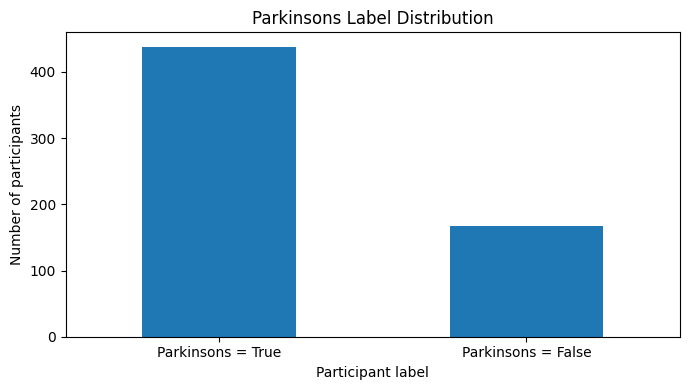


Participant audit preview:


,participant_id,monthly_log_files,first_year_month,last_year_month,metadata_filename,parkinsons_label,has_metadata,has_valid_label
0,04AUPVMQXY,1,1708,1708,NaN,<NA>,False,False
1,0EA27ICBLF,2,1607,1608,User_0EA27ICBLF.txt,True,True,True
2,0JIWJUQ4ZN,1,1703,1703,User_0JIWJUQ4ZN.txt,False,True,True
3,0M2T2Q0WQF,1,1704,1704,NaN,<NA>,False,False
4,0NMZ9JBBHI,3,1608,1610,NaN,<NA>,False,False
5,0NPYYFR8TU,2,1710,1711,User_0NPYYFR8TU.txt,False,True,True
6,0QAZFRHQHW,7,1609,1708,User_0QAZFRHQHW.txt,True,True,True
7,0SQJZGEL9V,1,1704,1704,User_0SQJZGEL9V.txt,True,True,True
8,0TCP0AM6NO,3,1708,1710,User_0TCP0AM6NO.txt,True,True,True
9,0WTTDFEZZ3,1,1709,1709,User_0WTTDFEZZ3.txt,True,True,True


In [15]:
log_participants = set(
    log_manifest["participant_id"]
)

metadata_participants = set(
    metadata_df_unique["participant_id"]
)


matched_ids = (
    log_participants & metadata_participants
)

logs_without_metadata = (
    log_participants - metadata_participants
)

metadata_without_logs = (
    metadata_participants - log_participants
)


participant_log_summary = (
    log_manifest
    .groupby("participant_id")
    .agg(
        monthly_log_files=("filename", "count"),
        first_year_month=("year_month", "min"),
        last_year_month=("year_month", "max"),
    )
    .reset_index()
)


participant_audit = participant_log_summary.merge(
    metadata_df_unique[
        [
            "participant_id",
            "metadata_filename",
            "parkinsons_label"
        ]
    ],
    on="participant_id",
    how="left",
    validate="one_to_one"
)


participant_audit["has_metadata"] = (
    participant_audit["metadata_filename"].notna()
)

participant_audit["has_valid_label"] = (
    participant_audit["parkinsons_label"].notna()
)


print("Unique log participants:", len(log_participants))
print("Unique metadata participants:", len(metadata_participants))
print("Participants in both sources:", len(matched_ids))

print(
    "Log participants without metadata:",
    len(logs_without_metadata)
)

print(
    "Metadata participants without logs:",
    len(metadata_without_logs)
)

print(
    "Log participants with valid labels:",
    int(participant_audit["has_valid_label"].sum())
)


print("\nLog participants without metadata:")
print(sorted(logs_without_metadata)[:30])


print("\nMetadata participants without logs:")
print(sorted(metadata_without_logs)[:30])


label_counts = (
    participant_audit.loc[
        participant_audit["has_valid_label"],
        "parkinsons_label"
    ]
    .value_counts()
    .rename_axis("parkinsons_label")
    .rename("participants")
    .reset_index()
)


print("\nParticipant label distribution:")
display(label_counts)


if not label_counts.empty:

    readable_labels = (
        participant_audit.loc[
            participant_audit["has_valid_label"],
            "parkinsons_label"
        ]
        .map({
            True: "Parkinsons = True",
            False: "Parkinsons = False"
        })
        .value_counts()
    )

    ax = readable_labels.plot(
        kind="bar",
        figsize=(7, 4),
        rot=0,
        title="Parkinsons Label Distribution"
    )

    ax.set_xlabel("Participant label")
    ax.set_ylabel("Number of participants")

    plt.tight_layout()
    plt.show()


print("\nParticipant audit preview:")
display(participant_audit.head(10))

## 6. Inspect a Sample Keystroke Log

Each raw event is expected to contain eight whitespace-separated fields:

1. Participant ID
2. Date
3. Time
4. Hand
5. Hold time
6. Direction
7. Latency time
8. Flight time

The timing values are expected to be represented in milliseconds.

This section reads only a few records. It does not load an entire monthly log into memory.

In [16]:
LOG_COLUMNS = [
    "participant_id",
    "date",
    "time",
    "hand",
    "hold_time_ms",
    "direction",
    "latency_time_ms",
    "flight_time_ms",
]


sample_path = log_files[0]

print("Sample log filename:", sample_path.name)

sample_records = []


with sample_path.open(
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as file:

    for line in file:

        if not line.strip():
            continue

        parts = re.split(r"\s+", line.strip())

        record = {
            column: (
                parts[index]
                if index < len(parts)
                else pd.NA
            )
            for index, column in enumerate(LOG_COLUMNS)
        }

        record["field_count"] = len(parts)

        sample_records.append(record)

        if len(sample_records) >= 10:
            break


sample_df = pd.DataFrame(sample_records)

display(sample_df)


if sample_records:
    print(
        "Observed field counts:",
        Counter(
            record["field_count"]
            for record in sample_records
        )
    )
else:
    print("The selected log file contains no nonblank records.")

Sample log filename: 04AUPVMQXY_1708.txt


,participant_id,date,time,hand,hold_time_ms,direction,latency_time_ms,flight_time_ms,field_count
0,04AUPVMQXY,170823,08:12:27.529,L,0103.5,LL,0375.0,0263.7,8
1,04AUPVMQXY,170823,08:12:27.738,L,0103.5,LL,0209.0,0105.5,8
2,04AUPVMQXY,170823,08:12:28.002,R,0080.1,LR,0287.1,0183.6,8
3,04AUPVMQXY,170823,08:12:28.322,R,0121.1,RR,0279.3,0199.2,8
4,04AUPVMQXY,170823,08:12:28.754,R,0087.9,RR,0464.8,0343.8,8
5,04AUPVMQXY,170823,08:12:29.146,L,0103.5,RL,0377.0,0289.1,8
6,04AUPVMQXY,170823,08:12:29.580,S,0185.5,LS,0351.6,0248.0,8
7,04AUPVMQXY,170823,08:12:30.730,L,0144.5,RL,0279.3,0183.6,8
8,04AUPVMQXY,170823,08:12:31.082,S,0209.0,LS,0287.1,0142.6,8
9,04AUPVMQXY,170823,08:12:33.105,L,0175.8,RL,0263.7,0144.5,8


Observed field counts: Counter({8: 10})


## 7. Full Data-Quality Scan

This section scans each recognized monthly log line by line.

It checks:
- Number of fields per event
- Participant ID consistency
- Date and time format
- Valid hand categories
- Numeric timing values
- Non-finite timing values
- Nonpositive hold times
- Negative latency and flight times
- File read errors

Potentially unusual timing values are flagged for investigation, not automatically removed.

In particular, negative flight times can arise from overlapping keystrokes depending on the dataset's event definitions. Their meaning must be reviewed rather than assuming every negative value is a data-entry error.

This full scan may take some time because it reads the contents of every monthly file.

In [17]:
quality_rows = []

total_event_rows = 0
total_blank_lines = 0
total_malformed_rows = 0
total_id_mismatches = 0
total_invalid_dates = 0
total_invalid_times = 0
total_invalid_hands = 0
total_timing_parse_errors = 0
total_nonfinite_timing_rows = 0
total_nonpositive_hold_rows = 0
total_negative_latency_rows = 0
total_negative_flight_rows = 0
total_read_errors = 0


def is_valid_date(value):
    if not re.fullmatch(r"\d{6}", value):
        return False

    try:
        datetime.strptime(value, "%y%m%d")
        return True
    except ValueError:
        return False


def is_valid_time(value):
    formats = (
        "%H:%M:%S.%f",
        "%H:%M:%S"
    )

    for fmt in formats:
        try:
            datetime.strptime(value, fmt)
            return True
        except ValueError:
            pass

    return False


for file_index, path in enumerate(
    log_files,
    start=1
):

    filename_match = LOG_FILENAME_RE.match(path.name)

    filename_pid = filename_match.group(
        "participant_id"
    ).upper()

    rows = 0
    blank_lines = 0
    malformed_rows = 0
    id_mismatches = 0
    invalid_dates = 0
    invalid_times = 0
    invalid_hands = 0
    timing_parse_errors = 0
    nonfinite_timing_rows = 0
    nonpositive_hold_rows = 0
    negative_latency_rows = 0
    negative_flight_rows = 0

    read_error = None

    min_hold = None
    max_hold = None

    min_latency = None
    max_latency = None

    min_flight = None
    max_flight = None


    try:

        with path.open(
            "r",
            encoding="utf-8-sig",
            errors="replace"
        ) as file:

            for line in file:

                if not line.strip():
                    blank_lines += 1
                    continue

                parts = re.split(
                    r"\s+",
                    line.strip()
                )

                rows += 1

                # A valid row is expected to contain eight fields.
                if len(parts) != 8:
                    malformed_rows += 1
                    continue

                # Check participant ID against the filename.
                if parts[0].upper() != filename_pid:
                    id_mismatches += 1

                # Validate the recorded date and time.
                if not is_valid_date(parts[1]):
                    invalid_dates += 1

                if not is_valid_time(parts[2]):
                    invalid_times += 1

                # The expected hand categories are L, R, or S.
                if parts[3].upper() not in {"L", "R", "S"}:
                    invalid_hands += 1

                # Convert timing columns to floating-point values.
                timing_values = []
                parse_failed = False

                for value in (
                    parts[4],
                    parts[6],
                    parts[7]
                ):
                    try:
                        timing_values.append(float(value))
                    except (TypeError, ValueError):
                        timing_values.append(np.nan)
                        parse_failed = True

                if parse_failed:
                    timing_parse_errors += 1
                    continue

                hold, latency, flight = timing_values

                if not all(
                    np.isfinite(value)
                    for value in timing_values
                ):
                    nonfinite_timing_rows += 1
                    continue

                # Track timing ranges for this file.
                if min_hold is None:

                    min_hold = max_hold = hold

                    min_latency = max_latency = latency

                    min_flight = max_flight = flight

                else:

                    min_hold = min(min_hold, hold)
                    max_hold = max(max_hold, hold)

                    min_latency = min(min_latency, latency)
                    max_latency = max(max_latency, latency)

                    min_flight = min(min_flight, flight)
                    max_flight = max(max_flight, flight)

                # Flag unusual values for later investigation.
                if hold <= 0:
                    nonpositive_hold_rows += 1

                if latency < 0:
                    negative_latency_rows += 1

                if flight < 0:
                    negative_flight_rows += 1


    except OSError as error:

        read_error = str(error)
        total_read_errors += 1


    # Accumulate global counts.
    total_event_rows += rows
    total_blank_lines += blank_lines
    total_malformed_rows += malformed_rows
    total_id_mismatches += id_mismatches
    total_invalid_dates += invalid_dates
    total_invalid_times += invalid_times
    total_invalid_hands += invalid_hands
    total_timing_parse_errors += timing_parse_errors
    total_nonfinite_timing_rows += nonfinite_timing_rows
    total_nonpositive_hold_rows += nonpositive_hold_rows
    total_negative_latency_rows += negative_latency_rows
    total_negative_flight_rows += negative_flight_rows


    quality_rows.append({
        "filename": path.name,
        "participant_id_from_filename": filename_pid,
        "event_rows": rows,
        "blank_lines": blank_lines,
        "malformed_rows": malformed_rows,
        "participant_id_mismatches": id_mismatches,
        "invalid_date_rows": invalid_dates,
        "invalid_time_rows": invalid_times,
        "invalid_hand_rows": invalid_hands,
        "timing_parse_error_rows": timing_parse_errors,
        "nonfinite_timing_rows": nonfinite_timing_rows,
        "nonpositive_hold_rows": nonpositive_hold_rows,
        "negative_latency_rows": negative_latency_rows,
        "negative_flight_rows": negative_flight_rows,
        "min_hold_ms": min_hold,
        "max_hold_ms": max_hold,
        "min_latency_ms": min_latency,
        "max_latency_ms": max_latency,
        "min_flight_ms": min_flight,
        "max_flight_ms": max_flight,
        "read_error": read_error,
    })


    # Progress indicator.
    if file_index % 250 == 0 or file_index == len(log_files):
        print(
            f"Scanned {file_index:,} "
            f"of {len(log_files):,} files"
        )


raw_file_quality = pd.DataFrame(quality_rows)


print("\n========== FULL SCAN SUMMARY ==========")

print("Files scanned:", f"{len(raw_file_quality):,}")
print("Nonblank event rows:", f"{total_event_rows:,}")
print("Blank lines:", f"{total_blank_lines:,}")
print("Malformed rows:", f"{total_malformed_rows:,}")
print("Participant ID mismatches:", f"{total_id_mismatches:,}")
print("Invalid date rows:", f"{total_invalid_dates:,}")
print("Invalid time rows:", f"{total_invalid_times:,}")
print("Invalid hand rows:", f"{total_invalid_hands:,}")
print("Timing parse-error rows:", f"{total_timing_parse_errors:,}")
print("Non-finite timing rows:", f"{total_nonfinite_timing_rows:,}")
print("Nonpositive hold-time rows:", f"{total_nonpositive_hold_rows:,}")
print("Negative latency rows:", f"{total_negative_latency_rows:,}")
print("Negative flight rows:", f"{total_negative_flight_rows:,}")
print("Files with read errors:", f"{total_read_errors:,}")


print("\nFiles with the most potential data-quality issues:")

display(
    raw_file_quality.sort_values(
        [
            "malformed_rows",
            "participant_id_mismatches",
            "timing_parse_error_rows",
            "invalid_date_rows",
            "invalid_time_rows",
        ],
        ascending=False
    ).head(20)
)

Scanned 250 of 2,165 files
Scanned 500 of 2,165 files
Scanned 750 of 2,165 files
Scanned 1,000 of 2,165 files
Scanned 1,250 of 2,165 files
Scanned 1,500 of 2,165 files
Scanned 1,750 of 2,165 files
Scanned 2,000 of 2,165 files
Scanned 2,165 of 2,165 files

========== FULL SCAN SUMMARY ==========
Files scanned: 2,165
Nonblank event rows: 40,524,886
Blank lines: 0
Malformed rows: 7
Participant ID mismatches: 384
Invalid date rows: 291
Invalid time rows: 196,341
Invalid hand rows: 1,043
Timing parse-error rows: 464,803
Non-finite timing rows: 0
Nonpositive hold-time rows: 18,101
Negative latency rows: 0
Negative flight rows: 0
Files with read errors: 0

Files with the most potential data-quality issues:


,filename,participant_id_from_filename,event_rows,blank_lines,malformed_rows,participant_id_mismatches,invalid_date_rows,invalid_time_rows,invalid_hand_rows,timing_parse_error_rows,nonfinite_timing_rows,nonpositive_hold_rows,negative_latency_rows,negative_flight_rows,min_hold_ms,max_hold_ms,min_latency_ms,max_latency_ms,min_flight_ms,max_flight_ms,read_error
41,2JTCBKUP8T_1705.txt,2JTCBKUP8T,30194,0,3,1,0,1,1,3,0,0,0,0,3.9,6367.2,2.0,798.8,3.9,796.9,None
324,9JN39MOLWT_1709.txt,9JN39MOLWT,4426,0,1,3,0,4,4,8,0,0,0,0,3.9,306101.6,11.7,796.9,3.9,796.9,None
1463,QAH9IVALVC_1608.txt,QAH9IVALVC,10797,0,1,2,3,4,4,9,0,45,0,0,0.0,1105.5,11.7,484.4,11.7,484.4,None
1388,OMCPRWYBSQ_1610.txt,OMCPRWYBSQ,94971,0,1,0,1,4,4,7,0,0,0,0,1.0,486.3,2.0,798.8,1.0,796.9,None
533,CZGEWMX7XG_1709.txt,CZGEWMX7XG,658,0,1,0,0,0,0,0,0,0,0,0,23.4,187.5,132.8,796.9,11.7,714.8,None
42,2JTCBKUP8T_1706.txt,2JTCBKUP8T,17994,0,0,24,0,1,1,4,0,0,0,0,3.9,355.5,3.9,798.8,2.0,789.1,None
1234,MU88QXAXHS_1711.txt,MU88QXAXHS,44653,0,0,15,0,6,8,24,0,0,0,0,2.0,414.1,7.8,796.9,1.0,796.9,None
272,8EY6NZAKCI_1712.txt,8EY6NZAKCI,24557,0,0,14,5,15,17,45,0,67,0,0,0.0,816.4,3.9,498.0,2.0,498.0,None
40,2JTCBKUP8T_1704.txt,2JTCBKUP8T,18085,0,0,11,0,1,1,2,0,0,0,0,3.9,261.7,3.9,798.8,3.9,796.9,None
2033,YLMLNVBU1I_1710.txt,YLMLNVBU1I,10924,0,0,10,0,0,0,0,0,0,0,0,15.6,343.8,23.4,799.0,78.1,742.2,None


## 8. Summarize Timing Ranges and Data Quality

This section summarizes the minimum and maximum observed values across monthly files.

Ranges are useful for detecting parsing problems and unusual values. They do not, by themselves, establish clinically meaningful differences between participants.

In [18]:
timing_summary = pd.DataFrame([
    {
        "variable": "hold_time_ms",
        "minimum_across_files": (
            raw_file_quality["min_hold_ms"].min()
        ),
        "maximum_across_files": (
            raw_file_quality["max_hold_ms"].max()
        ),
    },
    {
        "variable": "latency_time_ms",
        "minimum_across_files": (
            raw_file_quality["min_latency_ms"].min()
        ),
        "maximum_across_files": (
            raw_file_quality["max_latency_ms"].max()
        ),
    },
    {
        "variable": "flight_time_ms",
        "minimum_across_files": (
            raw_file_quality["min_flight_ms"].min()
        ),
        "maximum_across_files": (
            raw_file_quality["max_flight_ms"].max()
        ),
    },
])


print("Observed timing ranges in milliseconds:")
display(timing_summary)


quality_totals = {
    "Files with malformed rows": int(
        (raw_file_quality["malformed_rows"] > 0).sum()
    ),

    "Files with participant ID mismatches": int(
        (
            raw_file_quality["participant_id_mismatches"] > 0
        ).sum()
    ),

    "Files with invalid dates": int(
        (
            raw_file_quality["invalid_date_rows"] > 0
        ).sum()
    ),

    "Files with invalid times": int(
        (
            raw_file_quality["invalid_time_rows"] > 0
        ).sum()
    ),

    "Files with timing parse errors": int(
        (
            raw_file_quality["timing_parse_error_rows"] > 0
        ).sum()
    ),

    "Empty monthly files": int(
        log_manifest["empty_file"].sum()
    ),
}


print("\nFile-level quality indicators:")

display(
    pd.DataFrame(
        list(quality_totals.items()),
        columns=[
            "quality_check",
            "number_of_files"
        ]
    )
)

Observed timing ranges in milliseconds:


,variable,minimum_across_files,maximum_across_files
0,hold_time_ms,-86399940.0,56730740.0
1,latency_time_ms,1.0,799.9
2,flight_time_ms,1.0,799.9



File-level quality indicators:


,quality_check,number_of_files
0,Files with malformed rows,5
1,Files with participant ID mismatches,206
2,Files with invalid dates,178
3,Files with invalid times,434
4,Files with timing parse errors,743
5,Empty monthly files,5


## 9. Save Audit Reports Locally

The notebook will save the following files to `reports/local_audit/`:

- `log_manifest.csv`
- `participant_audit.csv`
- `raw_file_quality.csv`
- `metadata_field_audit.csv`
- `metadata_parse_issues.csv`
- `audit_summary.json`

**Privacy warning:** These reports are for local analysis. Do not publicly commit raw health-related records, participant-level label reports, or other sensitive metadata without confirming permission and appropriate safeguards.

In [19]:
REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# 1. Monthly log manifest.
log_manifest.to_csv(
    REPORT_DIR / "log_manifest.csv",
    index=False
)


# 2. Participant-to-label join audit.
participant_audit.to_csv(
    REPORT_DIR / "participant_audit.csv",
    index=False
)


# 3. Per-file quality summary.
raw_file_quality.to_csv(
    REPORT_DIR / "raw_file_quality.csv",
    index=False
)


# 4. Metadata field availability summary.
# Export field names and missingness counts only, not raw metadata values.

metadata_excluded_columns = {
    "participant_id",
    "metadata_filename",
    "parkinsons_label",
}

metadata_fields = [
    column
    for column in metadata_df_unique.columns
    if column not in metadata_excluded_columns
]


metadata_field_rows = []

for field in metadata_fields:

    nonmissing = int(
        metadata_df_unique[field].notna().sum()
    )

    metadata_field_rows.append({
        "field": field,
        "nonmissing_records": nonmissing,
        "missing_records": (
            len(metadata_df_unique) - nonmissing
        ),
    })


metadata_field_audit = pd.DataFrame(
    metadata_field_rows
)

metadata_field_audit.to_csv(
    REPORT_DIR / "metadata_field_audit.csv",
    index=False
)


# 5. Metadata parsing issues.
pd.DataFrame(metadata_parse_issues).to_csv(
    REPORT_DIR / "metadata_parse_issues.csv",
    index=False
)


# 6. Valid label counts for participants represented in the logs.
valid_labels = participant_audit.loc[
    participant_audit["has_valid_label"],
    "parkinsons_label"
]

label_counts_for_json = {
    str(label): int(count)
    for label, count in valid_labels.value_counts().items()
}


audit_summary = {
    "project_root": str(PROJECT_ROOT),

    "recognized_monthly_log_files": int(
        len(log_manifest)
    ),

    "unique_log_participants": int(
        len(log_participants)
    ),

    "metadata_files": int(
        len(metadata_files)
    ),

    "unique_metadata_participants": int(
        metadata_df_unique["participant_id"].nunique()
    ),

    "participants_in_both_sources": int(
        len(matched_ids)
    ),

    "log_participants_without_metadata": int(
        len(logs_without_metadata)
    ),

    "metadata_participants_without_logs": int(
        len(metadata_without_logs)
    ),

    "participants_with_valid_labels_and_logs": int(
        participant_audit["has_valid_label"].sum()
    ),

    "participant_label_counts": label_counts_for_json,

    "event_rows_scanned": int(
        total_event_rows
    ),

    "blank_lines": int(
        total_blank_lines
    ),

    "malformed_rows": int(
        total_malformed_rows
    ),

    "participant_id_mismatches": int(
        total_id_mismatches
    ),

    "invalid_date_rows": int(
        total_invalid_dates
    ),

    "invalid_time_rows": int(
        total_invalid_times
    ),

    "invalid_hand_rows": int(
        total_invalid_hands
    ),

    "timing_parse_error_rows": int(
        total_timing_parse_errors
    ),

    "nonfinite_timing_rows": int(
        total_nonfinite_timing_rows
    ),

    "nonpositive_hold_rows": int(
        total_nonpositive_hold_rows
    ),

    "negative_latency_rows": int(
        total_negative_latency_rows
    ),

    "negative_flight_rows": int(
        total_negative_flight_rows
    ),

    "files_with_read_errors": int(
        total_read_errors
    ),

    "clinical_metadata_excluded_from_initial_predictors": [
        "tremors",
        "diagnosisyear",
        "updrs",
        "impact",
        "levodopa",
        "da",
        "maob",
        "other",
    ],

    "interpretation_note": (
        "Research dataset audit only. "
        "This project does not provide a clinical diagnosis."
    ),
}


with (
    REPORT_DIR / "audit_summary.json"
).open(
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        audit_summary,
        file,
        indent=2,
        ensure_ascii=False
    )


print("Audit reports saved to:")
print(REPORT_DIR)

print("\nSummary:")
print(
    json.dumps(
        audit_summary,
        indent=2,
        ensure_ascii=False
    )
)

Audit reports saved to:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit

Summary:
{
  "project_root": "C:\\ML project\\PARKINSONS-DISEASE-PREDICTOR",
  "recognized_monthly_log_files": 2165,
  "unique_log_participants": 754,
  "metadata_files": 646,
  "unique_metadata_participants": 646,
  "participants_in_both_sources": 609,
  "log_participants_without_metadata": 145,
  "metadata_participants_without_logs": 37,
  "participants_with_valid_labels_and_logs": 606,
  "participant_label_counts": {
    "True": 438,
    "False": 168
  },
  "event_rows_scanned": 40524886,
  "blank_lines": 0,
  "malformed_rows": 7,
  "participant_id_mismatches": 384,
  "invalid_date_rows": 291,
  "invalid_time_rows": 196341,
  "invalid_hand_rows": 1043,
  "timing_parse_error_rows": 464803,
  "nonfinite_timing_rows": 0,
  "nonpositive_hold_rows": 18101,
  "negative_latency_rows": 0,
  "negative_flight_rows": 0,
  "files_with_read_errors": 0,
  "clinical_metadata_excluded_from_initial_predictors": [

In [20]:
print("=== UNRECOGNIZED PARKINSONS LABELS ===")

invalid_labels = metadata_df[
    metadata_df["parkinsons_label"].isna()
][
    ["participant_id", "metadata_filename", "parkinsons"]
].copy()

display(invalid_labels)

print("\nRaw Parkinsons field value counts:")
display(
    metadata_df["parkinsons"]
    .fillna("<MISSING>")
    .astype(str)
    .value_counts(dropna=False)
)


# Diagnostic 2: Select files with the most recorded issues.
# Use separate rankings so we do not overlook a different issue category.

issue_columns = [
    "timing_parse_error_rows",
    "invalid_time_rows",
    "participant_id_mismatches",
    "invalid_date_rows",
    "invalid_hand_rows",
]

top_names = set()

for column in issue_columns:
    if column in raw_file_quality.columns:
        ranked = raw_file_quality.sort_values(
            column, ascending=False
        ).head(8)

        top_names.update(ranked["filename"].tolist())

print("\nFiles selected for raw-record inspection:", len(top_names))


# Diagnostic 3: Inspect raw records containing one or more issues.
# Limit stored examples per category to keep the output manageable.

MAX_EXAMPLES_PER_CATEGORY = 8

examples = {
    "timing_parse_error": [],
    "invalid_time": [],
    "invalid_date": [],
    "participant_id_mismatch": [],
    "invalid_hand": [],
    "wrong_field_count": [],
}


def diagnostic_valid_date(value):
    if not re.fullmatch(r"\d{6}", value):
        return False

    try:
        datetime.strptime(value, "%y%m%d")
        return True
    except ValueError:
        return False


def diagnostic_valid_time(value):
    for fmt in ("%H:%M:%S.%f", "%H:%M:%S"):
        try:
            datetime.strptime(value, fmt)
            return True
        except ValueError:
            pass

    return False


selected_files = [
    p for p in log_files if p.name in top_names
]

for path in selected_files:

    filename_match = LOG_FILENAME_RE.fullmatch(path.name)
    filename_pid = filename_match.group("participant_id").upper()

    with path.open(
        "r",
        encoding="utf-8-sig",
        errors="replace"
    ) as file:

        for line_number, line in enumerate(file, start=1):

            if not line.strip():
                continue

            parts = re.split(r"\s+", line.strip())

            def save_example(category, details):
                if len(examples[category]) < MAX_EXAMPLES_PER_CATEGORY:
                    examples[category].append({
                        "filename": path.name,
                        "line_number": line_number,
                        "details": details,
                        "raw_record": line.strip()[:250],
                    })

            if len(parts) != 8:
                save_example(
                    "wrong_field_count",
                    f"Expected 8 fields; found {len(parts)}"
                )
                continue

            if parts[0].upper() != filename_pid:
                save_example(
                    "participant_id_mismatch",
                    f"Filename ID={filename_pid}; row ID={parts[0]}"
                )

            if not diagnostic_valid_date(parts[1]):
                save_example(
                    "invalid_date",
                    f"Date field={parts[1]!r}"
                )

            if not diagnostic_valid_time(parts[2]):
                save_example(
                    "invalid_time",
                    f"Time field={parts[2]!r}"
                )

            if parts[3].upper() not in {"L", "R", "S"}:
                save_example(
                    "invalid_hand",
                    f"Hand field={parts[3]!r}"
                )

            bad_timing_fields = []

            for column_name, value in [
                ("hold_time_ms", parts[4]),
                ("latency_time_ms", parts[6]),
                ("flight_time_ms", parts[7]),
            ]:
                try:
                    float(value)
                except (TypeError, ValueError):
                    bad_timing_fields.append(
                        f"{column_name}={value!r}"
                    )

            if bad_timing_fields:
                save_example(
                    "timing_parse_error",
                    "; ".join(bad_timing_fields)
                )


print("\n=== RAW RECORD EXAMPLES ===")

for category, records in examples.items():

    print(f"\n{category}: {len(records)} example(s)")

    if records:
        display(pd.DataFrame(records))
    else:
        print("No examples found in the selected files.")

=== UNRECOGNIZED PARKINSONS LABELS ===


,participant_id,metadata_filename,parkinsons
221,FXD2HCNIPJ,User_FXD2HCNIPJ.txt,
435,PVADT62JUM,User_PVADT62JUM.txt,
453,QIHPY6RIK3,User_QIHPY6RIK3.txt,



Raw Parkinsons field value counts:


parkinsons
True     455
False    188
           3
Name: count, dtype: int64


Files selected for raw-record inspection: 24

=== RAW RECORD EXAMPLES ===

timing_parse_error: 8 example(s)


...


participant_id_mismatch: 8 example(s)


,filename,line_number,details,raw_record
0,2JTCBKUP8T_1704.txt,10710,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170410\t23:23:47.359\tL\t0132.8\tRL\t04...
1,2JTCBKUP8T_1704.txt,11496,Filename ID=2JTCBKUP8T; row ID=               ...,                                              ...
2,2JTCBKUP8T_1704.txt,11618,Filename ID=2JTCBKUP8T; row ID=               ...,                                              ...
3,2JTCBKUP8T_1704.txt,11983,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170421\t07:29:03.182\tR\t0097.7\tLR\t05...
4,2JTCBKUP8T_1704.txt,12440,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170422\t23:31:29.234\tL\t0101.6\tRL\t05...
5,2JTCBKUP8T_1704.txt,12526,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170423\t19:49:24.945\tS\t0078.1\tLS\t04...
6,2JTCBKUP8T_1704.txt,13983,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170424\t23:00:39.367\tL\t0093.8\tLL\t03...
7,2JTCBKUP8T_1704.txt,17073,Filename ID=2JTCBKUP8T; row ID=KUP8T,KUP8T\t170425\t21:54:29.219\tR\t0085.9\tLR\t02...



invalid_hand: 8 example(s)


,filename,line_number,details,raw_record
0,2JTCBKUP8T_1704.txt,10574,Hand field='170410',2JTCBKUP8T\t170410\t17:37:15.9                ...
1,2JTCBKUP8T_1706.txt,13559,Hand field='170627',2JTCBKUP8T\t170627\t1                         ...
2,8EY6NZAKCI_1712.txt,1307,Hand field='15:11:45.180',8EY6NZAKCI\t8EY6NZAKCI\t171201\t15:11:45.180\t...
3,8EY6NZAKCI_1712.txt,1787,Hand field='06:21:25.021',8EY6NZAKCI\t8EY6NZAKCI\t171203\t06:21:25.021\t...
4,8EY6NZAKCI_1712.txt,1942,Hand field='10:01:03.285',8EY6NZAKCI\t8EY6NZAKCI\t171203\t10:01:03.285\t...
5,8EY6NZAKCI_1712.txt,3014,Hand field='171203',8EY6NZAKCI\t171203\t18:53:33.58EY6NZAKCI\t1712...
6,8EY6NZAKCI_1712.txt,6052,Hand field='8EY6NZAKCI',8EY6NZAKCI\t171205\t20:23:01.156\t8EY6NZAKCI\t...
7,8EY6NZAKCI_1712.txt,6295,Hand field='171206',8EY6NZAKCI\t171205\t23:14:3                   ...



wrong_field_count: 0 example(s)
No examples found in the selected files.


In [21]:
# Diagnostic 2: Inspect suspicious raw records at the byte level.
# This cell does NOT modify the original dataset.

suspect_lines = {
    "2JTCBKUP8T_1704.txt": [327, 10574, 10710, 11983],
    "2JTCBKUP8T_1706.txt": [13559],
    "8EY6NZAKCI_1712.txt": [1307, 1787, 1942, 3014, 6295, 14963],
    "95S93AXF86_1703.txt": [8166, 8976, 12260],
}

for filename, target_lines in suspect_lines.items():

    path = LOG_DIR / filename

    print("\n" + "=" * 90)
    print("FILE:", filename)

    if not path.is_file():
        print("File not found:", path)
        continue

    targets = set(target_lines)

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            if line_number not in targets:
                continue

            raw = raw_line.rstrip(b"\r\n")

            # Decode while preserving invalid bytes in escaped form.
            decoded = raw.decode(
                "utf-8",
                errors="backslashreplace"
            )

            fields = (
                re.split(r"\s+", decoded.strip())
                if decoded.strip()
                else []
            )

            print(f"\nLine number: {line_number}")
            print("Raw byte length:", len(raw))
            print("NUL byte count:", raw.count(b"\x00"))
            print("Whitespace-separated field count:", len(fields))
            print("Raw record:", repr(decoded[:400]))

            print("Fields:")
            for index, value in enumerate(fields):
                print(f"  Field {index + 1}: {value[:100]!r}")


FILE: 2JTCBKUP8T_1704.txt

Line number: 327
Raw byte length: 393
NUL byte count: 328
Whitespace-separated field count: 8
Raw record: '2JTCBKUP8T\t170401\t20:03:36.797\tL\t0101.\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0

In [22]:
# Participant-level label audit.
# Do not count missing labels as False.

print("=== LABELED PARTICIPANT COHORT ===")

valid_participants = participant_audit[
    participant_audit["has_valid_label"]
].copy()

print("Participants with valid labels:", len(valid_participants))

print("\nLabel counts:")
print(
    valid_participants["parkinsons_label"]
    .value_counts()
    .rename(index={
        True: "Parkinsons = True",
        False: "Parkinsons = False"
    })
)

print("\nMissing-label participants:")
display(
    metadata_df[
        metadata_df["parkinsons_label"].isna()
    ][
        ["participant_id", "metadata_filename", "parkinsons"]
    ]
)

print("\nDuplicate metadata records:", len(duplicate_metadata_ids))

=== LABELED PARTICIPANT COHORT ===
Participants with valid labels: 606

Label counts:
parkinsons_label
Parkinsons = True     438
Parkinsons = False    168
Name: count, dtype: Int64

Missing-label participants:


,participant_id,metadata_filename,parkinsons
221,FXD2HCNIPJ,User_FXD2HCNIPJ.txt,
435,PVADT62JUM,User_PVADT62JUM.txt,
453,QIHPY6RIK3,User_QIHPY6RIK3.txt,



Duplicate metadata records: 0


## 10. Diagnosis 3 — Dataset-Wide NUL-Byte Analysis

### Objective

Determine how widespread NUL-byte corruption is across the monthly keystroke logs.

Earlier byte-level inspection found records containing NUL bytes (`0x00`), including records in which timing values or timestamps appeared corrupted.

The previous inspection examined selected records only. This analysis scans all recognized monthly log files to quantify the issue.

### Measurements

For each file, calculate:

- Total physical lines.
- Nonblank lines.
- Number of lines containing at least one NUL byte.
- Total number of NUL bytes.
- Whether the file contains any NUL bytes.

A limited number of suspicious records will be displayed for manual inspection.

### Important

This scan reads the source files in binary mode. It does not remove NUL bytes, repair records, or overwrite any raw data.

The results will help establish whether the issue is isolated to particular files or more widespread.

In [23]:
# Diagnosis 3: Dataset-wide NUL-byte analysis.
# This cell reads raw files only. It performs no cleaning or repair.

NUL_EXAMPLES_LIMIT = 40

nul_audit_rows = []
nul_record_examples = []

total_physical_lines = 0
total_nonblank_lines = 0
total_lines_with_nul = 0
total_nul_bytes = 0

for file_index, path in enumerate(log_files, start=1):

    physical_lines = 0
    nonblank_lines = 0
    lines_with_nul = 0
    nul_bytes = 0

    try:
        with path.open("rb") as file:

            for line_number, raw_line in enumerate(file, start=1):

                physical_lines += 1

                # Remove only line-ending bytes for inspection.
                raw = raw_line.rstrip(b"\r\n")

                if not raw.strip():
                    continue

                nonblank_lines += 1

                nul_count = raw.count(b"\x00")

                if nul_count > 0:

                    lines_with_nul += 1
                    nul_bytes += nul_count

                    # Store only a limited number of examples in memory.
                    if len(nul_record_examples) < NUL_EXAMPLES_LIMIT:

                        decoded = raw.decode(
                            "utf-8",
                            errors="backslashreplace"
                        )

                        fields = (
                            re.split(r"\s+", decoded.strip())
                            if decoded.strip()
                            else []
                        )

                        nul_record_examples.append({
                            "filename": path.name,
                            "line_number": line_number,
                            "nul_byte_count": nul_count,
                            "field_count": len(fields),
                            "record_preview": repr(decoded[:250])
                        })

    except OSError as error:

        nul_audit_rows.append({
            "filename": path.name,
            "physical_lines": None,
            "nonblank_lines": None,
            "lines_with_nul": None,
            "nul_bytes": None,
            "contains_nul": None,
            "read_error": str(error)
        })

        continue

    total_physical_lines += physical_lines
    total_nonblank_lines += nonblank_lines
    total_lines_with_nul += lines_with_nul
    total_nul_bytes += nul_bytes

    nul_audit_rows.append({
        "filename": path.name,
        "physical_lines": physical_lines,
        "nonblank_lines": nonblank_lines,
        "lines_with_nul": lines_with_nul,
        "nul_bytes": nul_bytes,
        "contains_nul": lines_with_nul > 0,
        "read_error": None
    })

    # Print occasional progress without flooding notebook output.
    if file_index % 100 == 0 or file_index == len(log_files):

        print(
            f"Scanned {file_index:,} of {len(log_files):,} files"
        )


# Convert results into a report.
nul_audit_df = pd.DataFrame(nul_audit_rows)

print("\n" + "=" * 70)
print("DATASET-WIDE NUL-BYTE AUDIT")
print("=" * 70)

print("Files discovered:", f"{len(log_files):,}")
print("Files successfully scanned:", int(nul_audit_df["read_error"].isna().sum()))
print("Files with read errors:", int(nul_audit_df["read_error"].notna().sum()))
print("Physical lines scanned:", f"{total_physical_lines:,}")
print("Nonblank lines scanned:", f"{total_nonblank_lines:,}")
print("Lines containing NUL bytes:", f"{total_lines_with_nul:,}")
print("Total NUL bytes:", f"{total_nul_bytes:,}")

affected_files = int(
    nul_audit_df["contains_nul"]
    .fillna(False)
    .sum()
)

print("Files containing NUL bytes:", f"{affected_files:,}")

if total_nonblank_lines > 0:

    nul_line_percentage = (
        total_lines_with_nul / total_nonblank_lines
    ) * 100

    print(
        "Percentage of nonblank lines containing NUL bytes:",
        f"{nul_line_percentage:.6f}%"
    )


print("\nTop files by number of lines containing NUL bytes:")

display(
    nul_audit_df.sort_values(
        ["lines_with_nul", "nul_bytes"],
        ascending=False,
        na_position="last"
    ).head(25)
)


print("\nLimited examples of raw records containing NUL bytes:")

if nul_record_examples:

    display(pd.DataFrame(nul_record_examples))

else:

    print("No NUL bytes were detected in the scanned records.")


# Save the per-file summary to the existing local audit-report directory.
REPORT_DIR.mkdir(parents=True, exist_ok=True)

nul_report_path = REPORT_DIR / "nul_byte_audit.csv"

nul_audit_df.to_csv(
    nul_report_path,
    index=False
)

print("\nPer-file report saved to:")
print(nul_report_path)

print("\nNUL-byte diagnosis completed. Raw files were not modified.")

Scanned 100 of 2,165 files
Scanned 200 of 2,165 files
Scanned 300 of 2,165 files
Scanned 400 of 2,165 files
Scanned 500 of 2,165 files
Scanned 600 of 2,165 files
Scanned 700 of 2,165 files
Scanned 800 of 2,165 files
Scanned 900 of 2,165 files
Scanned 1,000 of 2,165 files
Scanned 1,100 of 2,165 files
Scanned 1,200 of 2,165 files
Scanned 1,300 of 2,165 files
Scanned 1,400 of 2,165 files
Scanned 1,500 of 2,165 files
Scanned 1,600 of 2,165 files
Scanned 1,700 of 2,165 files
Scanned 1,800 of 2,165 files
Scanned 1,900 of 2,165 files
Scanned 2,000 of 2,165 files
Scanned 2,100 of 2,165 files
Scanned 2,165 of 2,165 files

DATASET-WIDE NUL-BYTE AUDIT
Files discovered: 2,165
Files successfully scanned: 2165
Files with read errors: 0
Physical lines scanned: 40,524,886
Nonblank lines scanned: 40,524,886
Lines containing NUL bytes: 92
Total NUL bytes: 36,040
Files containing NUL bytes: 34
Percentage of nonblank lines containing NUL bytes: 0.000227%

Top files by number of lines containing NUL bytes:

,filename,physical_lines,nonblank_lines,lines_with_nul,nul_bytes,contains_nul,read_error
1234,MU88QXAXHS_1711.txt,44653,44653,32,8466,True,None
1233,MU88QXAXHS_1710.txt,38080,38080,10,2538,True,None
1324,NWPUCNVBVP_1712.txt,4610,4610,4,6107,True,None
1235,MU88QXAXHS_1712.txt,50200,50200,4,1876,True,None
42,2JTCBKUP8T_1706.txt,17994,17994,4,1002,True,None
40,2JTCBKUP8T_1704.txt,18085,18085,4,605,True,None
41,2JTCBKUP8T_1705.txt,30194,30194,3,356,True,None
2033,YLMLNVBU1I_1710.txt,10924,10924,2,1321,True,None
1554,QSKHVWX4YV_1710.txt,4617,4617,2,860,True,None
669,F9TRKWHCFH_1709.txt,3674,3674,2,670,True,None



Limited examples of raw records containing NUL bytes:


,filename,line_number,nul_byte_count,field_count,record_preview
0,2JTCBKUP8T_1702.txt,8785,7,8,'2JTCBKUP8T\t170225\t16:23:12.797\tR\t0128.9\t...
1,2JTCBKUP8T_1703.txt,6960,196,8,'2JTCBKUP8T\t170306\t09:54:28.301\tS\t0097.7\t...
2,2JTCBKUP8T_1704.txt,327,328,8,'2JTCBKUP8T\t170401\t20:03:36.797\tL\t0101.\x0...
3,2JTCBKUP8T_1704.txt,10574,33,8,'2JTCBKUP8T\t170410\t17:37:15.9\x00\x00\x00\x0...
4,2JTCBKUP8T_1704.txt,11496,122,8,'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\...
5,2JTCBKUP8T_1704.txt,11618,122,8,'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\...
6,2JTCBKUP8T_1705.txt,18202,21,8,'2JTCBKUP8T\t170511\t15:09:06.035\tL\t0078.1\t...
7,2JTCBKUP8T_1705.txt,26373,296,8,'2JTCBKUP8\x00\x00\x00\x00\x00\x00\x00\x00\x00...
8,2JTCBKUP8T_1705.txt,28770,39,8,'2JTCBKUP8T\t170528\t09:3\x00\x00\x00\x00\x00\...
9,2JTCBKUP8T_1706.txt,704,350,8,'2JTCBKUP\x00\x00\x00\x00\x00\x00\x00\x00\x00\...



Per-file report saved to:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\nul_byte_audit.csv

NUL-byte diagnosis completed. Raw files were not modified.


## 11. Diagnosis 4 — Complete NUL-Containing Record Inventory

### Objective

Inspect every raw event line containing at least one NUL byte.

The previous scan identified 92 affected lines across 34 files. This step collects all those lines and checks their field structure and contents.

### Checks

- Number and location of NUL bytes.
- Number of parsed fields.
- Participant ID consistency with the filename.
- Date and timestamp format.
- Hand-field validity.
- Numeric timing-field validity.
- Possible participant-ID strings embedded in other fields.
- Records consisting only of NUL bytes or whitespace.

### Output

The complete diagnostic inventory will be saved as:

`nul_record_inventory.csv`

The original raw files remain unchanged. A flagged record is not automatically repaired or deleted.

In [25]:
# Diagnosis 4: Inventory every record containing NUL bytes.
# Read-only scan of only the 34 files identified in the previous cell.
import math
nul_file_names = set(
    nul_audit_df.loc[
        nul_audit_df["contains_nul"].fillna(False),
        "filename"
    ].astype(str)
)

nul_inventory_rows = []

def validate_date_diagnostic(value):
    if not re.fullmatch(r"\d{6}", value or ""):
        return False

    try:
        datetime.strptime(value, "%y%m%d")
        return True
    except ValueError:
        return False


def validate_time_diagnostic(value):
    if not re.fullmatch(
        r"\d{2}:\d{2}:\d{2}(?:\.\d+)?",
        value or ""
    ):
        return False

    try:
        datetime.strptime(value, "%H:%M:%S.%f")
        return True
    except ValueError:
        try:
            datetime.strptime(value, "%H:%M:%S")
            return True
        except ValueError:
            return False


for path in log_files:

    if path.name not in nul_file_names:
        continue

    filename_match = LOG_FILENAME_RE.match(path.name)

    if filename_match is None:
        continue

    expected_pid = filename_match.group(
        "participant_id"
    ).upper()

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            nul_count = raw.count(b"\x00")

            if nul_count == 0:
                continue

            decoded = raw.decode(
                "utf-8",
                errors="backslashreplace"
            )

            fields = (
                re.split(r"\s+", decoded.strip())
                if decoded.strip()
                else []
            )

            flags = []

            # Flag the presence of NUL bytes.
            flags.append("contains_nul_byte")

            # Identify records that contain no meaningful non-NUL content.
            remaining_bytes = raw.replace(b"\x00", b"")

            if not remaining_bytes.strip():
                flags.append("nul_only_or_whitespace_record")

            if len(fields) != 8:
                flags.append("field_count_not_eight")

            if fields:

                actual_pid = fields[0].upper()

                if actual_pid != expected_pid:
                    flags.append("participant_id_mismatch")

                # Flag occurrences of the filename participant ID
                # in fields other than the first field.
                if any(
                    expected_pid in value.upper()
                    for value in fields[1:]
                ):
                    flags.append(
                        "participant_id_appears_in_other_field"
                    )

            if len(fields) >= 2:
                if not validate_date_diagnostic(fields[1]):
                    flags.append("invalid_date_field")

            if len(fields) >= 3:
                if not validate_time_diagnostic(fields[2]):
                    flags.append("invalid_time_field")

            if len(fields) >= 4:
                if fields[3].upper() not in {"L", "R", "S"}:
                    flags.append("invalid_hand_field")

            # Expected positions, using zero-based Python indexing:
            # hold = 4, latency = 6, flight = 7.
            timing_fields = {
                4: "hold_time",
                6: "latency_time",
                7: "flight_time",
            }

            if len(fields) == 8:

                for index, field_name in timing_fields.items():

                    try:
                        value = float(fields[index])

                        if not math.isfinite(value):
                            flags.append(
                                f"{field_name}_not_finite"
                            )

                        elif (
                            field_name == "hold_time"
                            and value <= 0
                        ):
                            flags.append(
                                "hold_time_not_positive"
                            )

                        elif (
                            field_name in {
                                "latency_time",
                                "flight_time"
                            }
                            and value < 0
                        ):
                            flags.append(
                                f"{field_name}_negative"
                            )

                    except (ValueError, TypeError):
                        flags.append(
                            f"{field_name}_not_numeric"
                        )

            nul_field_positions = [
                index + 1
                for index, value in enumerate(fields)
                if "\x00" in value
            ]

            nul_inventory_rows.append({
                "filename": path.name,
                "line_number": line_number,
                "expected_participant_id": expected_pid,
                "record_participant_id": (
                    fields[0] if fields else None
                ),
                "nul_byte_count": nul_count,
                "nul_field_positions": ",".join(
                    map(str, nul_field_positions)
                ),
                "field_count": len(fields),
                "flags": "; ".join(flags),
                "raw_record_preview": repr(decoded[:600]),
            })


nul_inventory_df = pd.DataFrame(nul_inventory_rows)

print("NUL-containing records inspected:", len(nul_inventory_df))
print(
    "Unique affected files:",
    nul_inventory_df["filename"].nunique()
    if not nul_inventory_df.empty else 0
)

print("\nDiagnostic flag counts:")

if not nul_inventory_df.empty:

    flag_counts = (
        nul_inventory_df["flags"]
        .str.split("; ")
        .explode()
        .value_counts()
        .rename_axis("diagnostic_flag")
        .reset_index(name="record_count")
    )

    display(flag_counts)

    print("\nComplete NUL record inventory:")
    display(
        nul_inventory_df.sort_values(
            ["filename", "line_number"]
        )
    )

else:
    print("No NUL-containing records were found.")

# Save the report locally without modifying raw files.
REPORT_DIR.mkdir(parents=True, exist_ok=True)

nul_inventory_path = (
    REPORT_DIR / "nul_record_inventory.csv"
)

nul_inventory_df.to_csv(
    nul_inventory_path,
    index=False
)

print("\nSaved diagnostic inventory:")
print(nul_inventory_path)

print("\nRaw data modified: No")

NUL-containing records inspected: 92
Unique affected files: 34

Diagnostic flag counts:


,diagnostic_flag,record_count
0,contains_nul_byte,92
1,participant_id_appears_in_other_field,57
2,latency_time_not_numeric,53
3,hold_time_not_numeric,36
4,participant_id_mismatch,28
5,invalid_hand_field,25
6,flight_time_not_numeric,22
7,invalid_time_field,21
8,invalid_date_field,4



Complete NUL record inventory:


,filename,line_number,expected_participant_id,record_participant_id,nul_byte_count,nul_field_positions,field_count,flags,raw_record_preview
0,2JTCBKUP8T_1702.txt,8785,2JTCBKUP8T,2JTCBKUP8T,7,8,8,contains_nul_byte; participant_id_appears_in_o...,'2JTCBKUP8T\t170225\t16:23:12.797\tR\t0128.9\t...
1,2JTCBKUP8T_1703.txt,6960,2JTCBKUP8T,2JTCBKUP8T,196,7,8,contains_nul_byte; participant_id_appears_in_o...,'2JTCBKUP8T\t170306\t09:54:28.301\tS\t0097.7\t...
2,2JTCBKUP8T_1704.txt,327,2JTCBKUP8T,2JTCBKUP8T,328,5,8,contains_nul_byte; participant_id_appears_in_o...,'2JTCBKUP8T\t170401\t20:03:36.797\tL\t0101.\x0...
3,2JTCBKUP8T_1704.txt,10574,2JTCBKUP8T,2JTCBKUP8T,33,3,8,contains_nul_byte; participant_id_appears_in_o...,'2JTCBKUP8T\t170410\t17:37:15.9\x00\x00\x00\x0...
4,2JTCBKUP8T_1704.txt,11496,2JTCBKUP8T,                                              ...,122,1,8,contains_nul_byte; participant_id_mismatch,'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\...
...,...,...,...,...,...,...,...,...,...
87,XWAX2IHF3O_1607.txt,40348,XWAX2IHF3O,XWAX2IHF3O,166,2,8,contains_nul_byte; participant_id_appears_in_o...,'XWAX2IHF3O\t160713\x00\x00\x00\x00\x00\x00\x0...
88,YLMLNVBU1I_1710.txt,69,YLMLNVBU1I,YLMLNVBU1                                     ...,958,1,8,contains_nul_byte; participant_id_mismatch,'YLMLNVBU1\x00\x00\x00\x00\x00\x00\x00\x00\x00...
89,YLMLNVBU1I_1710.txt,10220,YLMLNVBU1I,YLM                                           ...,363,1,8,contains_nul_byte; participant_id_mismatch,'YLM\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x...
90,YO2ED7XAE3_1712.txt,1894,YO2ED7XAE3,YO2ED7XAE3,318,3,8,contains_nul_byte; participant_id_appears_in_o...,'YO2ED7XAE3\t171211\t14:27:\x00\x00\x00\x00\x0...



Saved diagnostic inventory:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\nul_record_inventory.csv

Raw data modified: No


## 12. Diagnosis 5 — Dataset-Wide Record Structure Validation

### Objective

Check the structure and field contents of every monthly log record using the original tab delimiters.

The earlier diagnosis found records with NUL bytes, misplaced participant IDs, invalid timestamps, and nonnumeric timing fields. Some suspicious rows still appeared to contain eight whitespace-separated fields.

### Checks

- Number of tab-delimited fields per record.
- Participant ID consistency with the filename.
- Date and timestamp validity.
- Valid hand values.
- Numeric and finite hold, latency, and flight times.
- Nonpositive hold times and negative latency or flight times.
- NUL bytes and participant IDs embedded in other fields.

### Method

Read the raw files in binary mode and split records on literal tab characters. Remove only trailing empty fields caused by the record's trailing tab for field-count analysis.

This is a diagnostic operation only. It does not remove NUL bytes, repair values, delete records, or modify raw files.

### Outputs

- `record_structure_audit.csv`
- `record_structure_examples.csv`

These reports will help determine the extent of structural and value-level problems before cleaning policies are defined.

In [26]:
# Diagnosis 5: Dataset-wide tab-delimited structural audit.
# READ-ONLY: no raw records are repaired or modified.

from collections import Counter
from datetime import datetime
import math
import re

MAX_EXAMPLES_PER_FLAG = 8
MAX_TOTAL_EXAMPLES = 250

global_flag_counts = Counter()
field_count_distribution = Counter()
sampled_flag_counts = Counter()

structure_summary_rows = []
structure_example_rows = []

total_records_scanned = 0
total_records_with_issues = 0
total_nul_bytes_found = 0
total_read_errors = 0


def decode_field(raw_field):
    """Decode a raw field without removing embedded NUL bytes."""
    return raw_field.decode(
        "utf-8",
        errors="replace"
    ).strip()


def valid_date_field(value):
    if not re.fullmatch(r"\d{6}", value or ""):
        return False

    try:
        datetime.strptime(value, "%y%m%d")
        return True
    except ValueError:
        return False


def valid_time_field(value):
    if not re.fullmatch(
        r"\d{2}:\d{2}:\d{2}(?:\.\d+)?",
        value or ""
    ):
        return False

    try:
        if "." in value:
            datetime.strptime(value, "%H:%M:%S.%f")
        else:
            datetime.strptime(value, "%H:%M:%S")

        return True

    except ValueError:
        return False


for file_index, path in enumerate(log_files, start=1):

    filename_match = LOG_FILENAME_RE.match(path.name)

    if filename_match is None:
        continue

    expected_pid = filename_match.group(
        "participant_id"
    ).upper()

    file_counts = Counter()
    file_records = 0
    file_records_with_issues = 0
    file_nul_bytes = 0
    file_read_error = None

    try:
        with path.open("rb") as file:

            for line_number, raw_line in enumerate(file, start=1):

                raw = raw_line.rstrip(b"\r\n")

                # Ignore genuinely blank/whitespace-only lines.
                # A NUL-only line is deliberately NOT ignored.
                if not raw.strip():
                    continue

                total_records_scanned += 1
                file_records += 1

                nul_count = raw.count(b"\x00")
                total_nul_bytes_found += nul_count
                file_nul_bytes += nul_count

                # Use actual tabs, not generic whitespace.
                raw_fields = raw.split(b"\t")

                # Some records have a trailing tab.
                # Remove trailing empty fields for field-count checks.
                while (
                    raw_fields
                    and raw_fields[-1].strip() == b""
                ):
                    raw_fields.pop()

                fields = [
                    decode_field(field)
                    for field in raw_fields
                ]

                field_count = len(fields)
                field_count_distribution[field_count] += 1

                flags = []

                if nul_count:
                    flags.append("contains_nul_byte")

                if field_count != 8:
                    flags.append("field_count_not_eight")

                # Participant identity checks.
                if fields:

                    if fields[0].upper() != expected_pid:
                        flags.append("participant_id_mismatch")

                    if any(
                        expected_pid in value.upper()
                        for value in fields[1:]
                    ):
                        flags.append(
                            "participant_id_in_non_id_field"
                        )

                # Check positions only when the record has
                # exactly eight tab-delimited fields.
                if field_count == 8:

                    # Date: field 2.
                    if not valid_date_field(fields[1]):
                        flags.append("invalid_date")

                    # Time: field 3.
                    if not valid_time_field(fields[2]):
                        flags.append("invalid_time")

                    # Hand: field 4.
                    if fields[3].upper() not in {"L", "R", "S"}:
                        flags.append("invalid_hand")

                    # Timing values: fields 5, 7, and 8.
                    timing_indices = {
                        4: "hold_time",
                        6: "latency_time",
                        7: "flight_time",
                    }

                    for field_index, field_name in timing_indices.items():

                        try:
                            value = float(fields[field_index])

                            if not math.isfinite(value):
                                flags.append(
                                    f"{field_name}_not_finite"
                                )

                            elif (
                                field_name == "hold_time"
                                and value <= 0
                            ):
                                flags.append(
                                    "hold_time_not_positive"
                                )

                            elif (
                                field_name in {
                                    "latency_time",
                                    "flight_time"
                                }
                                and value < 0
                            ):
                                flags.append(
                                    f"{field_name}_negative"
                                )

                        except (ValueError, TypeError):
                            flags.append(
                                f"{field_name}_not_numeric"
                            )

                if flags:

                    total_records_with_issues += 1
                    file_records_with_issues += 1

                    file_counts["rows_with_any_issue"] += 1

                    for flag in flags:
                        global_flag_counts[flag] += 1
                        file_counts[flag] += 1

                if nul_count:
                    file_counts["rows_with_nul"] += 1
                    file_counts["nul_bytes"] += nul_count

                # Keep only a limited number of examples per issue type.
                should_store_example = (
                    bool(flags)
                    and len(structure_example_rows)
                    < MAX_TOTAL_EXAMPLES
                    and any(
                        sampled_flag_counts[flag]
                        < MAX_EXAMPLES_PER_FLAG
                        for flag in flags
                    )
                )

                if should_store_example:

                    structure_example_rows.append({
                        "filename": path.name,
                        "line_number": line_number,
                        "expected_participant_id": expected_pid,
                        "record_participant_id": (
                            fields[0] if fields else None
                        ),
                        "nul_byte_count": nul_count,
                        "field_count": field_count,
                        "flags": "; ".join(flags),
                        "raw_record_preview": repr(
                            raw.decode(
                                "utf-8",
                                errors="backslashreplace"
                            )[:400]
                        )
                    })

                    for flag in flags:
                        if (
                            sampled_flag_counts[flag]
                            < MAX_EXAMPLES_PER_FLAG
                        ):
                            sampled_flag_counts[flag] += 1

    except OSError as error:

        total_read_errors += 1
        file_read_error = str(error)

    summary_row = {
        "filename": path.name,
        "records_scanned": file_records,
        "rows_with_any_issue": file_records_with_issues,
        "rows_with_nul": file_counts["rows_with_nul"],
        "nul_bytes": file_nul_bytes,
        "field_count_not_eight": file_counts[
            "field_count_not_eight"
        ],
        "participant_id_mismatch": file_counts[
            "participant_id_mismatch"
        ],
        "invalid_date": file_counts["invalid_date"],
        "invalid_time": file_counts["invalid_time"],
        "invalid_hand": file_counts["invalid_hand"],
        "hold_time_not_numeric": file_counts[
            "hold_time_not_numeric"
        ],
        "latency_time_not_numeric": file_counts[
            "latency_time_not_numeric"
        ],
        "flight_time_not_numeric": file_counts[
            "flight_time_not_numeric"
        ],
        "read_error": file_read_error
    }

    structure_summary_rows.append(summary_row)

    if file_index % 100 == 0 or file_index == len(log_files):
        print(
            f"Scanned {file_index:,} of {len(log_files):,} files"
        )


# Build diagnostic output tables.
record_structure_audit = pd.DataFrame(
    structure_summary_rows
)

record_structure_examples = pd.DataFrame(
    structure_example_rows
)

print("\n" + "=" * 75)
print("TAB-DELIMITED STRUCTURAL AUDIT")
print("=" * 75)

print("Files discovered:", f"{len(log_files):,}")
print("Records scanned:", f"{total_records_scanned:,}")
print(
    "Records with at least one flagged issue:",
    f"{total_records_with_issues:,}"
)
print("NUL bytes found:", f"{total_nul_bytes_found:,}")
print("Files with read errors:", total_read_errors)

print("\nField-count distribution:")

field_count_df = pd.DataFrame([
    {
        "field_count": count,
        "record_count": frequency
    }
    for count, frequency in sorted(
        field_count_distribution.items()
    )
])

display(field_count_df)

print("\nIssue counts:")
flag_count_df = pd.DataFrame([
    {
        "diagnostic_flag": flag,
        "affected_record_count": count
    }
    for flag, count in global_flag_counts.most_common()
])

if not flag_count_df.empty:
    display(flag_count_df)
else:
    print("No issues detected by these checks.")

print("\nFiles with the highest number of flagged records:")

display(
    record_structure_audit.sort_values(
        ["rows_with_any_issue", "rows_with_nul"],
        ascending=False
    ).head(25)
)

print("\nExamples of flagged records:")

if not record_structure_examples.empty:
    display(record_structure_examples)
else:
    print("No examples to display.")


# Save diagnostic reports; raw files remain untouched.
REPORT_DIR.mkdir(parents=True, exist_ok=True)

structure_audit_path = (
    REPORT_DIR / "record_structure_audit.csv"
)

structure_examples_path = (
    REPORT_DIR / "record_structure_examples.csv"
)

record_structure_audit.to_csv(
    structure_audit_path,
    index=False
)

record_structure_examples.to_csv(
    structure_examples_path,
    index=False
)

print("\nReports saved:")
print(structure_audit_path)
print(structure_examples_path)

print("\nDiagnostic scan completed. No raw data was modified.")

Scanned 100 of 2,165 files
Scanned 200 of 2,165 files
Scanned 300 of 2,165 files
Scanned 400 of 2,165 files
Scanned 500 of 2,165 files
Scanned 600 of 2,165 files
Scanned 700 of 2,165 files
Scanned 800 of 2,165 files
Scanned 900 of 2,165 files
Scanned 1,000 of 2,165 files
Scanned 1,100 of 2,165 files
Scanned 1,200 of 2,165 files
Scanned 1,300 of 2,165 files
Scanned 1,400 of 2,165 files
Scanned 1,500 of 2,165 files
Scanned 1,600 of 2,165 files
Scanned 1,700 of 2,165 files
Scanned 1,800 of 2,165 files
Scanned 1,900 of 2,165 files
Scanned 2,000 of 2,165 files
Scanned 2,100 of 2,165 files
Scanned 2,165 of 2,165 files

TAB-DELIMITED STRUCTURAL AUDIT
Files discovered: 2,165
Records scanned: 40,524,886
Records with at least one flagged issue: 483,295
NUL bytes found: 36,040
Files with read errors: 0

Field-count distribution:


,field_count,record_count
0,7,4
1,8,40524882



Issue counts:


,diagnostic_flag,affected_record_count
0,latency_time_not_numeric,464119
1,hold_time_not_numeric,463674
2,flight_time_not_numeric,463529
3,invalid_time,196341
4,hold_time_not_positive,18102
5,participant_id_in_non_id_field,2309
6,invalid_hand,1043
7,participant_id_mismatch,387
8,invalid_date,291
9,contains_nul_byte,92



Files with the highest number of flagged records:


,filename,records_scanned,rows_with_any_issue,rows_with_nul,nul_bytes,field_count_not_eight,participant_id_mismatch,invalid_date,invalid_time,invalid_hand,hold_time_not_numeric,latency_time_not_numeric,flight_time_not_numeric,read_error
832,HFHL1NVADQ_1711.txt,118695,96762,0,0,0,1,0,96761,1,96761,96761,96760,None
831,HFHL1NVADQ_1710.txt,92236,84013,1,452,0,0,0,84011,0,84012,84013,84011,None
1392,OPACZPPV1Q_1711.txt,38425,38425,0,0,0,0,0,0,0,38425,38425,38425,None
1053,KM4FAMJWJ3_1705.txt,35800,35800,0,0,0,0,0,0,0,35800,35800,35800,None
1413,PDKF0GKH59_1711.txt,32447,32447,0,0,0,0,0,1,1,32447,32447,32447,None
1393,OPACZPPV1Q_1712.txt,30553,30553,0,0,0,0,0,0,0,30553,30553,30553,None
848,HQW5YE0PUK_1711.txt,19778,19778,0,0,0,0,0,1,1,19778,19776,19777,None
1412,PDKF0GKH59_1710.txt,17221,17221,0,0,0,0,0,0,0,17221,17221,17221,None
617,EIFBUG1US3_1710.txt,16540,16540,0,0,0,0,0,0,0,16540,16540,16540,None
1052,KM4FAMJWJ3_1704.txt,15685,15685,0,0,0,0,0,0,0,15685,15685,15685,None



Examples of flagged records:


,filename,line_number,expected_participant_id,record_participant_id,nul_byte_count,field_count,flags,raw_record_preview
0,0EA27ICBLF_1607.txt,2651,0EA27ICBLF,0EA27ICB0EA27ICBLF,0,8,participant_id_mismatch,'0EA27ICB0EA27ICBLF\t160723\t17:35:20.516\tL\t...
1,0EA27ICBLF_1607.txt,14482,0EA27ICBLF,0EA27ICBLF,0,8,flight_time_not_numeric,'0EA27ICBLF\t160729\t22:17:34.477\tL\t0093.8\t...
2,0EA27ICBLF_1607.txt,24138,0EA27ICBLF,0EA27ICBLF,0,8,participant_id_in_non_id_field; hold_time_not_...,'0EA27ICBLF\t160729\t22:01:40.578\tS\t00EA27IC...
3,0EA27ICBLF_1607.txt,34201,0EA27ICBLF,0EA27ICBLF,0,8,flight_time_not_numeric,'0EA27ICBLF\t160730\t03:36:10.631\tR\t0066.4\t...
4,0EA27ICBLF_1607.txt,35769,0EA27ICBLF,0EA27ICBLF,0,8,participant_id_in_non_id_field; invalid_time; ...,'0EA27ICBLF\t160731\t13:25:17.6680EA27ICBLF\t1...
5,0EA27ICBLF_1607.txt,45832,0EA27ICBLF,0EA27ICBLF,0,8,flight_time_not_numeric,'0EA27ICBLF\t160730\t03:36:10.631\tR\t0066.4\t...
6,0EA27ICBLF_1607.txt,47703,0EA27ICBLF,0EA27ICBLF,0,8,participant_id_in_non_id_field; latency_time_n...,'0EA27ICBLF\t160731\t20:06:38.547\tR\t0078.1\t...
7,0EA27ICBLF_1607.txt,57766,0EA27ICBLF,0EA27ICBLF,0,8,flight_time_not_numeric,'0EA27ICBLF\t160730\t03:36:10.631\tR\t0066.4\t...
8,0EA27ICBLF_1607.txt,59394,0EA27ICBLF,0EA27ICBLF,0,8,participant_id_in_non_id_field; hold_time_not_...,'0EA27ICBLF\t160731\t13:28:03.488\tS\t0105.0EA...
9,0EA27ICBLF_1607.txt,69457,0EA27ICBLF,0EA27ICBLF,0,8,flight_time_not_numeric,'0EA27ICBLF\t160730\t03:36:10.631\tR\t0066.4\t...



Reports saved:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\record_structure_audit.csv
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\record_structure_examples.csv

Diagnostic scan completed. No raw data was modified.


## 13. Diagnosis 6 — Detect Concatenated and Shifted Records

### Objective

Identify records in which participant IDs or other field contents appear in unexpected positions.

Previous investigations found records with eight whitespace-separated fields even though their dates, timestamps, or timing values were invalid.

### Checks

- Participant IDs appearing in non-ID fields.
- Participant IDs that differ from the filename.
- Participant-like text embedded in date or time fields.
- Unexpected tab-delimited field counts.
- Suspicious records that may contain concatenated event fragments.

The scan covers the entire monthly-log collection, including records without NUL bytes.

Flagged records are candidates for further investigation. They are not automatically classified as recoverable or discarded.

In [27]:
# Diagnosis 6: Search for concatenation and field-shift candidates.
# Read-only scan. Original raw files remain unchanged.

from collections import Counter
import re
import pandas as pd

MAX_CONCAT_EXAMPLES = 500

concat_flag_counts = Counter()
concat_examples = []
total_concat_candidates = 0


def decode_tab_fields(raw_record):
    fields = raw_record.split(b"\t")

    # Ignore trailing empty fields produced by trailing tabs.
    while fields and not fields[-1].strip():
        fields.pop()

    return [
        value.decode("utf-8", errors="backslashreplace").strip()
        for value in fields
    ]


for file_index, path in enumerate(log_files, start=1):

    match = LOG_FILENAME_RE.match(path.name)
    if match is None:
        continue

    expected_pid = match.group("participant_id").upper()

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            if not raw.strip():
                continue

            fields = decode_tab_fields(raw)
            flags = []

            if len(fields) != 8:
                flags.append("tab_field_count_not_eight")

            if not fields or fields[0].upper() != expected_pid:
                flags.append("participant_id_mismatch")

            embedded_positions = [
                index + 1
                for index, value in enumerate(fields[1:], start=1)
                if expected_pid in value.upper()
            ]

            if embedded_positions:
                flags.append("expected_id_inside_non_id_field")

            if len(fields) >= 2:
                date_value = fields[1]

                # Possible participant ID or other text appended to a date.
                if (
                    not re.fullmatch(r"\d{6}", date_value)
                    and re.search(r"[A-Za-z]", date_value)
                ):
                    flags.append("text_inside_date_field")

            if len(fields) >= 3:
                time_value = fields[2]

                if (
                    not re.fullmatch(
                        r"\d{2}:\d{2}:\d{2}(?:\.\d+)?",
                        time_value
                    )
                    and re.search(r"[A-Za-z]", time_value)
                ):
                    flags.append("text_inside_time_field")

            # Count all diagnostic flags, but store only strong candidates.
            for flag in flags:
                concat_flag_counts[flag] += 1

            strong_candidate = any(
                flag in flags
                for flag in [
                    "tab_field_count_not_eight",
                    "participant_id_mismatch",
                    "expected_id_inside_non_id_field",
                    "text_inside_date_field",
                    "text_inside_time_field",
                ]
            )

            if strong_candidate:
                total_concat_candidates += 1

                if len(concat_examples) < MAX_CONCAT_EXAMPLES:
                    concat_examples.append({
                        "filename": path.name,
                        "line_number": line_number,
                        "expected_participant_id": expected_pid,
                        "record_participant_id": (
                            fields[0] if fields else None
                        ),
                        "nul_byte_count": raw.count(b"\x00"),
                        "tab_field_count": len(fields),
                        "embedded_id_positions": ",".join(
                            map(str, embedded_positions)
                        ),
                        "flags": "; ".join(flags),
                        "raw_record": repr(
                            raw.decode(
                                "utf-8",
                                errors="backslashreplace"
                            )[:500]
                        )
                    })

    if file_index % 200 == 0 or file_index == len(log_files):
        print(f"Scanned {file_index:,} / {len(log_files):,} files")


concat_flag_df = pd.DataFrame([
    {"diagnostic_flag": flag, "count": count}
    for flag, count in concat_flag_counts.most_common()
])

concat_examples_df = pd.DataFrame(concat_examples)

print("\nCandidate records flagged:", f"{total_concat_candidates:,}")
print("Candidate examples retained:", len(concat_examples_df))

print("\nFlag counts:")
display(concat_flag_df)

print("\nCandidate examples:")
if not concat_examples_df.empty:
    display(concat_examples_df)
else:
    print("No candidates found by these rules.")

REPORT_DIR.mkdir(parents=True, exist_ok=True)

concat_examples_df.to_csv(
    REPORT_DIR / "concatenation_shift_examples.csv",
    index=False
)

concat_flag_df.to_csv(
    REPORT_DIR / "concatenation_shift_flag_counts.csv",
    index=False
)

print("\nReports saved under:", REPORT_DIR)
print("Raw data modified: No")

Scanned 200 / 2,165 files
Scanned 400 / 2,165 files
Scanned 600 / 2,165 files
Scanned 800 / 2,165 files
Scanned 1,000 / 2,165 files
Scanned 1,200 / 2,165 files
Scanned 1,400 / 2,165 files
Scanned 1,600 / 2,165 files
Scanned 1,800 / 2,165 files
Scanned 2,000 / 2,165 files
Scanned 2,165 / 2,165 files

Candidate records flagged: 2,702
Candidate examples retained: 500

Flag counts:


,diagnostic_flag,count
0,expected_id_inside_non_id_field,2309
1,text_inside_time_field,673
2,participant_id_mismatch,387
3,text_inside_date_field,291
4,tab_field_count_not_eight,4



Candidate examples:


,filename,line_number,expected_participant_id,record_participant_id,nul_byte_count,tab_field_count,embedded_id_positions,flags,raw_record
0,0EA27ICBLF_1607.txt,2651,0EA27ICBLF,0EA27ICB0EA27ICBLF,0,8,,participant_id_mismatch,'0EA27ICB0EA27ICBLF\t160723\t17:35:20.516\tL\t...
1,0EA27ICBLF_1607.txt,24138,0EA27ICBLF,0EA27ICBLF,0,8,5,expected_id_inside_non_id_field,'0EA27ICBLF\t160729\t22:01:40.578\tS\t00EA27IC...
2,0EA27ICBLF_1607.txt,35769,0EA27ICBLF,0EA27ICBLF,0,8,3,expected_id_inside_non_id_field; text_inside_t...,'0EA27ICBLF\t160731\t13:25:17.6680EA27ICBLF\t1...
3,0EA27ICBLF_1607.txt,47703,0EA27ICBLF,0EA27ICBLF,0,8,6,expected_id_inside_non_id_field,'0EA27ICBLF\t160731\t20:06:38.547\tR\t0078.1\t...
4,0EA27ICBLF_1607.txt,59394,0EA27ICBLF,0EA27ICBLF,0,8,5,expected_id_inside_non_id_field,'0EA27ICBLF\t160731\t13:28:03.488\tS\t0105.0EA...
...,...,...,...,...,...,...,...,...,...
495,9JRHCGCWAZ_1703.txt,7907,9JRHCGCWAZ,9JRHCGCWAZ,0,8,3,expected_id_inside_non_id_field; text_inside_t...,'9JRHCGCWAZ\t170305\t23:53:9JRHCGCWAZ\t170306\...
496,9JRHCGCWAZ_1703.txt,24681,9JRHCGCWAZ,9JRHCGCWAZ,0,8,2,expected_id_inside_non_id_field; text_inside_d...,'9JRHCGCWAZ\t1703159JRHCGCWAZ\t170315\t21:37:1...
497,9JRHCGCWAZ_1703.txt,27085,9JRHCGCWAZ,9JRHCGCWAZ9JRHCGCWAZ,0,8,,participant_id_mismatch,'9JRHCGCWAZ9JRHCGCWAZ\t170318\t21:34:07.719\tL...
498,9JRHCGCWAZ_1704.txt,25859,9JRHCGCWAZ,9J9JRHCGCWAZ,0,8,,participant_id_mismatch,'9J9JRHCGCWAZ\t170416\t11:34:39.754\tL\t0171.9...



Reports saved under: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit
Raw data modified: No


## 14. Diagnosis 7 — Date and Filename Consistency

### Objective

Check whether valid event dates agree with their monthly log filenames.

For each file, this diagnostic evaluates:

- Event dates with a valid six-digit format.
- Calendar-valid event dates.
- Valid dates whose year-month differs from the filename.
- Examples of inconsistent records.

A filename-month mismatch may indicate a shifted date field, appended text, or an issue with the source file.

The notebook records these inconsistencies without rewriting any dates.

In [28]:
# Diagnosis 7: Compare event dates with the month in each filename.

from datetime import datetime
from collections import Counter
import pandas as pd
import re

date_consistency_rows = []
date_mismatch_examples = []

total_valid_dates = 0
total_invalid_dates_for_check = 0
total_month_mismatches = 0

MAX_DATE_EXAMPLES = 200


def parse_valid_date(value):
    if not re.fullmatch(r"\d{6}", value or ""):
        return None

    try:
        return datetime.strptime(value, "%y%m%d").date()
    except ValueError:
        return None


for file_index, path in enumerate(log_files, start=1):

    match = LOG_FILENAME_RE.match(path.name)
    if match is None:
        continue

    expected_month = match.group("year_month")

    file_valid_dates = 0
    file_invalid_dates = 0
    file_month_mismatches = 0

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            if not raw.strip():
                continue

            fields = decode_tab_fields(raw)

            if len(fields) < 2:
                file_invalid_dates += 1
                total_invalid_dates_for_check += 1
                continue

            date_value = fields[1]
            event_date = parse_valid_date(date_value)

            if event_date is None:

                file_invalid_dates += 1
                total_invalid_dates_for_check += 1
                continue

            file_valid_dates += 1
            total_valid_dates += 1

            if date_value[:4] != expected_month:

                file_month_mismatches += 1
                total_month_mismatches += 1

                if len(date_mismatch_examples) < MAX_DATE_EXAMPLES:
                    date_mismatch_examples.append({
                        "filename": path.name,
                        "line_number": line_number,
                        "filename_year_month": expected_month,
                        "event_date": date_value,
                        "parsed_date": str(event_date),
                        "record_preview": repr(
                            raw.decode(
                                "utf-8",
                                errors="backslashreplace"
                            )[:300]
                        )
                    })

    date_consistency_rows.append({
        "filename": path.name,
        "valid_dates": file_valid_dates,
        "invalid_dates": file_invalid_dates,
        "valid_dates_outside_filename_month": file_month_mismatches
    })

    if file_index % 200 == 0 or file_index == len(log_files):
        print(f"Scanned {file_index:,} / {len(log_files):,} files")


date_consistency_df = pd.DataFrame(date_consistency_rows)
date_mismatch_df = pd.DataFrame(date_mismatch_examples)

print("\nValid dates:", f"{total_valid_dates:,}")
print("Invalid dates for this check:", f"{total_invalid_dates_for_check:,}")
print("Valid dates outside filename month:", f"{total_month_mismatches:,}")

print("\nFiles with the most date/month mismatches:")
display(
    date_consistency_df.sort_values(
        "valid_dates_outside_filename_month",
        ascending=False
    ).head(20)
)

print("\nDate/month mismatch examples:")
if not date_mismatch_df.empty:
    display(date_mismatch_df)
else:
    print("No valid event dates disagreed with the filename month.")

date_consistency_df.to_csv(
    REPORT_DIR / "date_consistency_by_file.csv",
    index=False
)

date_mismatch_df.to_csv(
    REPORT_DIR / "date_month_mismatch_examples.csv",
    index=False
)

print("\nReports saved under:", REPORT_DIR)
print("Raw data modified: No")

Scanned 200 / 2,165 files
Scanned 400 / 2,165 files
Scanned 600 / 2,165 files
Scanned 800 / 2,165 files
Scanned 1,000 / 2,165 files
Scanned 1,200 / 2,165 files
Scanned 1,400 / 2,165 files
Scanned 1,600 / 2,165 files
Scanned 1,800 / 2,165 files
Scanned 2,000 / 2,165 files
Scanned 2,165 / 2,165 files

Valid dates: 40,524,595
Invalid dates for this check: 291
Valid dates outside filename month: 0

Files with the most date/month mismatches:


,filename,valid_dates,invalid_dates,valid_dates_outside_filename_month
0,04AUPVMQXY_1708.txt,63,0,0
1,0EA27ICBLF_1607.txt,142635,0,0
2,0EA27ICBLF_1608.txt,15819,1,0
3,0JIWJUQ4ZN_1703.txt,156,0,0
4,0M2T2Q0WQF_1704.txt,28,0,0
5,0NMZ9JBBHI_1608.txt,877,0,0
6,0NMZ9JBBHI_1609.txt,4919,0,0
7,0NMZ9JBBHI_1610.txt,454,0,0
8,0NPYYFR8TU_1710.txt,214,0,0
9,0NPYYFR8TU_1711.txt,435,0,0



Date/month mismatch examples:
No valid event dates disagreed with the filename month.

Reports saved under: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit
Raw data modified: No


## 15. Diagnosis 8 — Chronological Ordering Analysis

### Objective

Check whether valid event timestamps are in chronological order within each monthly file.

The event date and time are combined into one timestamp. The diagnostic counts transitions in which a valid timestamp is earlier than the preceding valid timestamp.

### Interpretation

- Zero backward transitions: no reversals were detected among the valid timestamps examined.
- One or more backward transitions: inspect the relevant examples and determine whether the order is expected for the source format.
- Invalid dates and times are excluded from this particular comparison and remain part of the other diagnostic reports.

This check is not a cleaning operation and does not reorder events.

In [29]:
# Diagnosis 8: Check chronological order of valid event timestamps.
# This cell does not reorder records.

from datetime import datetime
import pandas as pd

chronology_file_rows = []
chronology_examples = []

total_valid_timestamps = 0
total_backward_transitions = 0

MAX_CHRONOLOGY_EXAMPLES = 200


def parse_valid_time(value):
    try:
        return datetime.strptime(value, "%H:%M:%S.%f").time()
    except ValueError:
        try:
            return datetime.strptime(value, "%H:%M:%S").time()
        except ValueError:
            return None


for file_index, path in enumerate(log_files, start=1):

    previous_timestamp = None
    previous_line_number = None

    file_valid_timestamps = 0
    file_backward_transitions = 0

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            if not raw.strip():
                continue

            fields = decode_tab_fields(raw)

            if len(fields) != 8:
                continue

            event_date = parse_valid_date(fields[1])
            event_time = parse_valid_time(fields[2])

            if event_date is None or event_time is None:
                continue

            timestamp = datetime.combine(event_date, event_time)

            file_valid_timestamps += 1
            total_valid_timestamps += 1

            if (
                previous_timestamp is not None
                and timestamp < previous_timestamp
            ):

                file_backward_transitions += 1
                total_backward_transitions += 1

                if len(chronology_examples) < MAX_CHRONOLOGY_EXAMPLES:
                    chronology_examples.append({
                        "filename": path.name,
                        "previous_line": previous_line_number,
                        "current_line": line_number,
                        "previous_timestamp": str(previous_timestamp),
                        "current_timestamp": str(timestamp),
                        "seconds_moved_backward": (
                            previous_timestamp - timestamp
                        ).total_seconds()
                    })

            previous_timestamp = timestamp
            previous_line_number = line_number

    chronology_file_rows.append({
        "filename": path.name,
        "valid_timestamps": file_valid_timestamps,
        "backward_transitions": file_backward_transitions
    })

    if file_index % 200 == 0 or file_index == len(log_files):
        print(f"Scanned {file_index:,} / {len(log_files):,} files")


chronology_by_file_df = pd.DataFrame(chronology_file_rows)
chronology_examples_df = pd.DataFrame(chronology_examples)

print("\nValid timestamps checked:", f"{total_valid_timestamps:,}")
print("Backward transitions detected:", f"{total_backward_transitions:,}")

print("\nFiles with the most backward transitions:")
display(
    chronology_by_file_df.sort_values(
        "backward_transitions",
        ascending=False
    ).head(20)
)

print("\nBackward-transition examples:")
if not chronology_examples_df.empty:
    display(chronology_examples_df)
else:
    print("No backward transitions were detected.")

chronology_by_file_df.to_csv(
    REPORT_DIR / "chronology_by_file.csv",
    index=False
)

chronology_examples_df.to_csv(
    REPORT_DIR / "chronology_examples.csv",
    index=False
)

print("\nReports saved under:", REPORT_DIR)
print("Raw data modified: No")

Scanned 200 / 2,165 files
Scanned 400 / 2,165 files
Scanned 600 / 2,165 files
Scanned 800 / 2,165 files
Scanned 1,000 / 2,165 files
Scanned 1,200 / 2,165 files
Scanned 1,400 / 2,165 files
Scanned 1,600 / 2,165 files
Scanned 1,800 / 2,165 files
Scanned 2,000 / 2,165 files
Scanned 2,165 / 2,165 files

Valid timestamps checked: 40,328,541
Backward transitions detected: 44,748

Files with the most backward transitions:


,filename,valid_timestamps,backward_transitions
643,EPDQVWTRZO_1712.txt,325619,482
728,G6OE5CXQPY_1701.txt,414785,434
1380,OHAKMKWIJI_1711.txt,233063,424
641,EPDQVWTRZO_1710.txt,332710,405
1288,NPACI6EW26_1611.txt,273273,375
1300,NPACI6EW26_1711.txt,311404,348
642,EPDQVWTRZO_1711.txt,252627,314
1299,NPACI6EW26_1710.txt,336470,307
1491,QCFNDCZPQH_1707.txt,207992,305
1775,U41OHVMD0I_1710.txt,242171,289



Backward-transition examples:


,filename,previous_line,current_line,previous_timestamp,current_timestamp,seconds_moved_backward
0,0EA27ICBLF_1607.txt,1640,1641,2016-07-22 21:23:17.781000,2016-07-22 21:23:17,0.781
1,0EA27ICBLF_1607.txt,2082,2083,2016-07-22 21:49:53.789000,2016-07-22 21:49:53,0.789
2,0EA27ICBLF_1607.txt,2257,2258,2016-07-22 21:56:56.578000,2016-07-22 21:56:56,0.578
3,0EA27ICBLF_1607.txt,2443,2444,2016-07-22 22:31:46.812000,2016-07-22 22:31:46,0.812
4,0EA27ICBLF_1607.txt,3648,3649,2016-07-24 14:25:11.387000,2016-07-23 17:35:20.516000,74990.871
...,...,...,...,...,...,...
195,1GRU4SWLUC_1710.txt,3213,3214,2017-10-25 13:36:48.625000,2017-10-25 13:36:48,0.625
196,1GRU4SWLUC_1710.txt,3571,3572,2017-10-26 12:30:52.805000,2017-10-26 12:30:52,0.805
197,1GRU4SWLUC_1710.txt,6267,6268,2017-10-31 12:24:13.766000,2017-10-31 12:24:13,0.766
198,1GRU4SWLUC_1711.txt,1759,1760,2017-11-02 10:27:57.734000,2017-11-02 10:27:57,0.734



Reports saved under: C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit
Raw data modified: No


## 16. Diagnosis 9 — Consolidated Findings and Readiness Review

### Objective

Bring together the results from the dataset audit and the subsequent diagnostic checks.

The report will summarize:

- Raw files and event records inspected.
- NUL-byte findings.
- Structural and field-content problems.
- Concatenation/shift candidates.
- Date/file-month mismatches.
- Chronological-order findings.
- Participant label availability.

### Decision rules

1. Do not automatically repair corrupted records.
2. Do not replace missing Parkinson's labels with `False`.
3. Do not use participant IDs or clinical metadata as initial model predictors.
4. Preserve all files in `data/raw/`.
5. Base future cleaning decisions on evidence and document the reason for each exclusion or transformation.

### Project status

- Dataset audit: Completed.
- Raw-data diagnosis: In progress until the results have been reviewed.
- Data cleaning: Not started.
- Feature engineering: Not started.
- Model training and evaluation: Not started.

In [30]:
# Diagnosis 9: Create a consolidated, local diagnostic summary.

from pathlib import Path
import json
import pandas as pd

diagnosis_summary = {
    "project_root": str(PROJECT_ROOT),
    "raw_data_modified": False,
    "monthly_log_files_discovered": int(len(log_files)),
    "metadata_files_discovered": int(len(metadata_files)),

    "nul_diagnosis": {
        "files_with_nul_bytes": int(
            nul_audit_df["contains_nul"].fillna(False).sum()
        ),
        "records_containing_nul": int(len(nul_inventory_df)),
        "total_nul_bytes": int(
            nul_audit_df["nul_bytes"].fillna(0).sum()
        )
    },

    "tab_structure_diagnosis": {
        "records_with_any_flag": int(
            record_structure_audit["rows_with_any_issue"].fillna(0).sum()
        ),
        "files_with_read_errors": int(
            record_structure_audit["read_error"].notna().sum()
        )
    },

    "concatenation_diagnosis": {
        "candidate_records_flagged": int(total_concat_candidates),
        "example_records_saved": int(len(concat_examples_df))
    },

    "date_consistency_diagnosis": {
        "valid_dates_checked": int(total_valid_dates),
        "invalid_dates_for_check": int(total_invalid_dates_for_check),
        "valid_dates_outside_filename_month": int(
            total_month_mismatches
        )
    },

    "chronology_diagnosis": {
        "valid_timestamps_checked": int(total_valid_timestamps),
        "backward_transitions": int(
            total_backward_transitions
        )
    },

    "next_stage": (
        "Review diagnostic evidence and document cleaning rules "
        "before modifying or excluding records."
    )
}

summary_path = REPORT_DIR / "consolidated_diagnosis_summary.json"

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(
        diagnosis_summary,
        file,
        indent=2,
        ensure_ascii=False
    )

print("CONSOLIDATED DIAGNOSIS SUMMARY")
print("=" * 55)

display(
    pd.json_normalize(
        diagnosis_summary,
        sep="."
    ).T.rename(columns={0: "value"})
)

print("\nSummary saved to:")
print(summary_path)

print("\nRaw files modified: No")
print("Data cleaning performed: No")

CONSOLIDATED DIAGNOSIS SUMMARY


,value
project_root,C:\ML project\PARKINSONS-DISEASE-PREDICTOR
raw_data_modified,False
monthly_log_files_discovered,2165
metadata_files_discovered,646
next_stage,Review diagnostic evidence and document cleani...
nul_diagnosis.files_with_nul_bytes,34
nul_diagnosis.records_containing_nul,92
nul_diagnosis.total_nul_bytes,36040
tab_structure_diagnosis.records_with_any_flag,483295
tab_structure_diagnosis.files_with_read_errors,0



Summary saved to:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\consolidated_diagnosis_summary.json

Raw files modified: No
Data cleaning performed: No


## 17. Diagnosis 10 — Refined Chronology Investigation

### Objective

Investigate the 44,748 backward transitions reported by the initial chronology scan.

### Classification

Classify backward transitions into:

- Same-second transitions where the current timestamp lacks fractional seconds.
- Other backward transitions of at most one second.
- Backward transitions exceeding one second within the same date.
- Transitions where the event date moves backward.
- Other timestamp reversals.

Also record the number of physical lines between each pair of valid timestamps.

### Interpretation

A transition with missing fractional seconds is not automatically a valid event or a corrupted event. It is a candidate requiring review.

A transition spanning skipped invalid rows must be distinguished from a reversal between adjacent source records.

This analysis is diagnostic only. It does not reorder, repair, or remove records.

In [31]:
# Diagnosis 10: Refine the chronology findings.
# No raw data is modified.

from collections import Counter
from datetime import datetime
import pandas as pd

chronology_backsteps = []
chronology_class_counts = Counter()

valid_timestamp_count = 0
backward_transition_count = 0

for file_index, path in enumerate(log_files, start=1):

    previous_timestamp = None
    previous_date = None
    previous_time_text = None
    previous_line_number = None

    filename_match = LOG_FILENAME_RE.match(path.name)

    if filename_match is None:
        continue

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            if not raw.strip():
                continue

            fields = decode_tab_fields(raw)

            # Match the original chronology scan's eligibility criteria.
            if len(fields) != 8:
                continue

            event_date = parse_valid_date(fields[1])
            event_time = parse_valid_time(fields[2])

            if event_date is None or event_time is None:
                # Preserve the previous valid timestamp.
                # The line gap will reveal skipped records.
                continue

            current_timestamp = datetime.combine(
                event_date,
                event_time
            )

            current_time_text = fields[2]

            valid_timestamp_count += 1

            if (
                previous_timestamp is not None
                and current_timestamp < previous_timestamp
            ):

                backward_transition_count += 1

                seconds_backward = (
                    previous_timestamp - current_timestamp
                ).total_seconds()

                line_gap = (
                    line_number - previous_line_number - 1
                )

                previous_clock_second = (
                    previous_time_text.split(".")[0]
                )

                current_clock_second = (
                    current_time_text.split(".")[0]
                )

                previous_has_fraction = (
                    "." in previous_time_text
                )

                current_has_fraction = (
                    "." in current_time_text
                )

                same_clock_second = (
                    previous_date == event_date
                    and previous_clock_second
                    == current_clock_second
                )

                if (
                    same_clock_second
                    and previous_has_fraction
                    and not current_has_fraction
                ):
                    category = (
                        "same_second_current_fraction_missing"
                    )

                elif seconds_backward <= 1:
                    category = "backward_at_most_one_second"

                elif event_date < previous_date:
                    category = "event_date_moved_backward"

                elif event_date == previous_date:
                    category = "same_date_backward_over_one_second"

                else:
                    category = "other_timestamp_reversal"

                chronology_class_counts[category] += 1

                chronology_backsteps.append({
                    "filename": path.name,
                    "previous_line": previous_line_number,
                    "current_line": line_number,
                    "skipped_physical_lines": line_gap,
                    "previous_timestamp": str(
                        previous_timestamp
                    ),
                    "current_timestamp": str(
                        current_timestamp
                    ),
                    "seconds_backward": seconds_backward,
                    "previous_time_had_fraction": (
                        previous_has_fraction
                    ),
                    "current_time_has_fraction": (
                        current_has_fraction
                    ),
                    "classification": category,
                })

            previous_timestamp = current_timestamp
            previous_date = event_date
            previous_time_text = current_time_text
            previous_line_number = line_number

    if file_index % 200 == 0 or file_index == len(log_files):
        print(
            f"Scanned {file_index:,} of "
            f"{len(log_files):,} files"
        )


chronology_backsteps_df = pd.DataFrame(
    chronology_backsteps
)

print("\nREFINED CHRONOLOGY RESULTS")
print("=" * 55)

print(
    "Valid timestamps checked:",
    f"{valid_timestamp_count:,}"
)

print(
    "Backward transitions:",
    f"{backward_transition_count:,}"
)

print(
    "Rows in the detailed reversal report:",
    f"{len(chronology_backsteps_df):,}"
)

if not chronology_backsteps_df.empty:

    print("\nClassification counts:")

    classification_summary = (
        chronology_backsteps_df["classification"]
        .value_counts()
        .rename_axis("classification")
        .reset_index(name="transition_count")
    )

    display(classification_summary)

    print("\nReversals involving skipped physical lines:")

    display(
        chronology_backsteps_df[
            chronology_backsteps_df[
                "skipped_physical_lines"
            ] > 0
        ].head(30)
    )

    print("\nLargest backward transitions:")

    display(
        chronology_backsteps_df.sort_values(
            "seconds_backward",
            ascending=False
        ).head(30)
    )

else:

    print("No backward transitions were found.")

REPORT_DIR.mkdir(parents=True, exist_ok=True)

refined_report_path = (
    REPORT_DIR / "chronology_all_backsteps.csv"
)

chronology_backsteps_df.to_csv(
    refined_report_path,
    index=False
)

print("\nDetailed chronology report saved to:")
print(refined_report_path)

print("\nRaw data modified: No")

Scanned 200 of 2,165 files
Scanned 400 of 2,165 files
Scanned 600 of 2,165 files
Scanned 800 of 2,165 files
Scanned 1,000 of 2,165 files
Scanned 1,200 of 2,165 files
Scanned 1,400 of 2,165 files
Scanned 1,600 of 2,165 files
Scanned 1,800 of 2,165 files
Scanned 2,000 of 2,165 files
Scanned 2,165 of 2,165 files

REFINED CHRONOLOGY RESULTS
Valid timestamps checked: 40,328,541
Backward transitions: 44,748
Rows in the detailed reversal report: 44,748

Classification counts:


,classification,transition_count
0,backward_at_most_one_second,44207
1,same_date_backward_over_one_second,458
2,event_date_moved_backward,83



Reversals involving skipped physical lines:


,filename,previous_line,current_line,skipped_physical_lines,previous_timestamp,current_timestamp,seconds_backward,previous_time_had_fraction,current_time_has_fraction,classification
24,0EA27ICBLF_1607.txt,35768,35770,1,2016-07-31 13:25:16.570000,2016-07-25 23:51:23.680000,480832.890,True,True,event_date_moved_backward
126,0EA27ICBLF_1608.txt,7706,7708,1,2016-08-13 00:47:35.784000,2016-08-10 00:30:32.030000,260223.754,True,True,event_date_moved_backward
15943,HFHL1NVADQ_1710.txt,2324,6412,4087,2017-10-11 05:24:25.918000,2017-10-11 05:24:17.510000,8.408,True,True,same_date_backward_over_one_second
15947,HFHL1NVADQ_1710.txt,7643,11623,3979,2017-10-13 08:14:30.629000,2017-10-13 08:13:38.684000,51.945,True,True,same_date_backward_over_one_second
15948,HFHL1NVADQ_1710.txt,11897,14828,2930,2017-10-13 16:30:45.145000,2017-10-13 16:25:04.918000,340.227,True,True,same_date_backward_over_one_second
15949,HFHL1NVADQ_1710.txt,15146,24880,9733,2017-10-15 01:42:05.805000,2017-10-15 01:42:02.981000,2.824,True,True,same_date_backward_over_one_second
15950,HFHL1NVADQ_1710.txt,25045,34959,9913,2017-10-15 13:16:27.914000,2017-10-15 13:16:11.898000,16.016,True,True,same_date_backward_over_one_second
15951,HFHL1NVADQ_1710.txt,35009,37980,2970,2017-10-17 03:05:04.876000,2017-10-17 03:05:00.937000,3.939,True,True,same_date_backward_over_one_second
15954,HFHL1NVADQ_1710.txt,39504,41925,2420,2017-10-18 10:21:14.434000,2017-10-18 10:21:11.527000,2.907,True,True,same_date_backward_over_one_second
15956,HFHL1NVADQ_1710.txt,42191,43574,1382,2017-10-19 09:26:51.320000,2017-10-19 02:19:23.428000,25647.892,True,True,same_date_backward_over_one_second



Largest backward transitions:


,filename,previous_line,current_line,skipped_physical_lines,previous_timestamp,current_timestamp,seconds_backward,previous_time_had_fraction,current_time_has_fraction,classification
44271,ZVGQ2EFVXC_1705.txt,2807,2808,0,2017-05-30 21:10:18.406000,2017-05-03 07:03:39.047000,2383599.359,True,True,event_date_moved_backward
31520,QFNEVLJ7N9_1705.txt,209,210,0,2017-05-29 15:40:13.184000,2017-05-07 20:48:03.773000,1882329.411,True,True,event_date_moved_backward
877,3NYRTBDECW_1711.txt,2701,2702,0,2017-11-14 06:48:54.289000,2017-11-03 10:47:57.641000,936056.648,True,True,event_date_moved_backward
18267,IDYIDJBAXF_1703.txt,5306,5307,0,2017-03-26 16:51:19.746000,2017-03-16 13:09:00.605000,877339.141,True,True,event_date_moved_backward
35656,SW9J12VYIW_1711.txt,19182,19183,0,2017-11-30 22:23:47.211000,2017-11-21 09:27:44.566000,824162.645,True,True,event_date_moved_backward
15754,HB2JCE24IE_1609.txt,1465,1466,0,2016-09-23 08:24:09.225000,2016-09-14 07:43:59.393000,780009.832,True,True,event_date_moved_backward
18936,JMIVIRFQRR_1609.txt,9550,9551,0,2016-09-30 23:10:22.734000,2016-09-22 22:59:43.234000,691839.500,True,True,event_date_moved_backward
7758,AVLBSQWBX6_1709.txt,9090,9091,0,2017-09-18 19:56:03.969000,2017-09-11 09:42:26.203000,641617.766,True,True,event_date_moved_backward
91,0EA27ICBLF_1607.txt,118473,118474,0,2016-07-31 20:17:51.969000,2016-07-25 23:51:23.680000,505588.289,True,True,event_date_moved_backward
81,0EA27ICBLF_1607.txt,106390,106391,0,2016-07-31 20:08:08.875000,2016-07-25 23:51:23.680000,505005.195,True,True,event_date_moved_backward



Detailed chronology report saved to:
C:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\chronology_all_backsteps.csv

Raw data modified: No


In [32]:
from pathlib import Path
from datetime import datetime
import math
import pandas as pd

# ---------------------------------------------------------
# 1. Locate the project and chronology report
# ---------------------------------------------------------

candidates = [Path.cwd(), *Path.cwd().parents,
              Path(r"C:\ML project\PARKINSONS-DISEASE-PREDICTOR")]

PROJECT_ROOT = next(
    (p for p in dict.fromkeys(candidates)
     if (p / "data" / "raw" / "keystroke_logs").is_dir()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Check the location of data/raw/keystroke_logs."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "keystroke_logs"
REPORT_DIR = PROJECT_ROOT / "reports" / "local_audit"
REPORT_PATH = REPORT_DIR / "chronology_all_backsteps.csv"

if not REPORT_PATH.exists():
    matches = list(
        (PROJECT_ROOT / "reports").rglob("chronology_all_backsteps.csv")
    )
    if not matches:
        raise FileNotFoundError(
            "chronology_all_backsteps.csv not found under reports/."
        )
    REPORT_PATH = matches[0]

transitions = pd.read_csv(REPORT_PATH, dtype=str).fillna("")

required_columns = {
    "filename",
    "previous_line",
    "current_line",
    "skipped_physical_lines",
    "previous_timestamp",
    "current_timestamp",
    "seconds_backward",
    "classification",
}

missing = required_columns - set(transitions.columns)
if missing:
    raise ValueError(f"Chronology report is missing columns: {sorted(missing)}")

print("Project root:", PROJECT_ROOT)
print("Chronology report:", REPORT_PATH)
print("Transitions loaded:", f"{len(transitions):,}")


# ---------------------------------------------------------
# 2. Helpers to validate a physical source record
# ---------------------------------------------------------

def to_line_number(value):
    try:
        number = int(value)
        return number if number > 0 else None
    except (TypeError, ValueError):
        return None


def parse_date(value):
    try:
        datetime.strptime(value, "%y%m%d")
        return True
    except (TypeError, ValueError):
        return False


def parse_time(value):
    for fmt in ("%H:%M:%S.%f", "%H:%M:%S"):
        try:
            datetime.strptime(value, fmt)
            return True
        except (TypeError, ValueError):
            pass
    return False


def inspect_record(raw_bytes, filename):
    text = raw_bytes.decode("utf-8", errors="replace").rstrip("\r\n")
    contains_nul = "\x00" in text
    fields = text.split("\t")

    # A single trailing tab is permitted by the observed source format.
    trailing_tab = bool(fields and fields[-1] == "")
    if trailing_tab:
        fields = fields[:-1]

    issues = []

    if len(fields) != 8:
        issues.append("field_count_not_8")

    expected_id = filename.rsplit("_", 1)[0]
    id_matches = bool(fields) and fields[0] == expected_id

    if not id_matches:
        issues.append("participant_id_mismatch")

    date_ok = len(fields) > 1 and parse_date(fields[1])
    if not date_ok:
        issues.append("invalid_date")

    time_ok = len(fields) > 2 and parse_time(fields[2])
    if not time_ok:
        issues.append("invalid_time")

    hand_ok = len(fields) > 3 and fields[3] in {"L", "R", "S"}
    if not hand_ok:
        issues.append("invalid_hand")

    numeric_ok = len(fields) >= 8
    if numeric_ok:
        for index in (4, 6, 7):
            try:
                numeric_value = float(fields[index])
                if not math.isfinite(numeric_value):
                    numeric_ok = False
                    break
            except (ValueError, TypeError):
                numeric_ok = False
                break

    if not numeric_ok:
        issues.append("invalid_numeric_timing")

    key_code_ok = len(fields) > 5 and bool(fields[5].strip())
    if not key_code_ok:
        issues.append("empty_key_code")

    if contains_nul:
        issues.append("contains_nul_byte")

    # Nonpositive hold time is reported separately; it is not
    # automatically classified as structural corruption.
    hold_nonpositive = False
    if len(fields) > 4:
        try:
            hold_nonpositive = float(fields[4]) <= 0
        except (ValueError, TypeError):
            pass

    return {
        "structurally_valid": len(issues) == 0,
        "field_count": len(fields),
        "trailing_tab": trailing_tab,
        "participant_id_matches": id_matches,
        "date_valid": date_ok,
        "time_valid": time_ok,
        "hand_valid": hand_ok,
        "numeric_timing_valid": numeric_ok,
        "contains_nul_byte": contains_nul,
        "hold_nonpositive": hold_nonpositive,
        "structural_issues": ";".join(issues),
    }


# ---------------------------------------------------------
# 3. Collect the specific physical lines we need to inspect
# ---------------------------------------------------------

lines_needed = {}

for row in transitions.itertuples(index=False):
    filename = row.filename
    lines_needed.setdefault(filename, set())

    previous_line = to_line_number(row.previous_line)
    current_line = to_line_number(row.current_line)

    if previous_line is not None:
        lines_needed[filename].add(previous_line)

    if current_line is not None:
        lines_needed[filename].add(current_line)


# Read each implicated raw file once and retain only relevant lines.
record_lookup = {}
missing_files = []

for filename, targets in lines_needed.items():
    raw_path = RAW_DIR / filename

    if not raw_path.is_file():
        missing_files.append(filename)
        continue

    remaining = set(targets)

    with raw_path.open("rb") as file:
        for line_number, raw_line in enumerate(file, start=1):
            if line_number in remaining:
                record_lookup[(filename, line_number)] = inspect_record(
                    raw_line, filename
                )
                remaining.remove(line_number)

            if not remaining:
                break

    if remaining:
        for line_number in remaining:
            record_lookup[(filename, line_number)] = None


# ---------------------------------------------------------
# 4. Classify each transition by endpoint record validity
# ---------------------------------------------------------

results = []

for row in transitions.to_dict("records"):
    filename = row["filename"]

    previous_line = to_line_number(row["previous_line"])
    current_line = to_line_number(row["current_line"])

    previous_record = (
        record_lookup.get((filename, previous_line))
        if previous_line is not None else None
    )
    current_record = (
        record_lookup.get((filename, current_line))
        if current_line is not None else None
    )

    if previous_record is None and current_record is None:
        status = "both_endpoints_unavailable"
    elif previous_record is None:
        status = "previous_endpoint_unavailable"
    elif current_record is None:
        status = "current_endpoint_unavailable"
    elif (
        previous_record["structurally_valid"]
        and current_record["structurally_valid"]
    ):
        status = "both_endpoints_valid"
    elif (
        not previous_record["structurally_valid"]
        and not current_record["structurally_valid"]
    ):
        status = "both_endpoints_invalid"
    elif not previous_record["structurally_valid"]:
        status = "previous_endpoint_invalid"
    else:
        status = "current_endpoint_invalid"

    skipped = to_line_number(row["skipped_physical_lines"]) or 0

    results.append({
        **row,
        "previous_structurally_valid": (
            previous_record["structurally_valid"]
            if previous_record else None
        ),
        "previous_structural_issues": (
            previous_record["structural_issues"]
            if previous_record else "endpoint_unavailable"
        ),
        "current_structurally_valid": (
            current_record["structurally_valid"]
            if current_record else None
        ),
        "current_structural_issues": (
            current_record["structural_issues"]
            if current_record else "endpoint_unavailable"
        ),
        "skipped_physical_lines_count": skipped,
        "has_skipped_physical_lines": skipped > 0,
        "endpoint_structure_class": status,
    })


# ---------------------------------------------------------
# 5. Save the cross-check reports
# ---------------------------------------------------------

crosscheck = pd.DataFrame(results)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

detail_path = REPORT_DIR / "chronology_structure_crosscheck.csv"
summary_path = REPORT_DIR / "chronology_structure_class_counts.csv"

crosscheck.to_csv(detail_path, index=False)

class_counts = (
    crosscheck["endpoint_structure_class"]
    .value_counts(dropna=False)
    .rename_axis("endpoint_structure_class")
    .reset_index(name="transition_count")
)

class_counts.to_csv(summary_path, index=False)

print("\nCROSS-CHECK SUMMARY")
print("=" * 55)
print("Transitions checked:", f"{len(crosscheck):,}")
print("Unique files:", f"{crosscheck['filename'].nunique():,}")
print(
    "Transitions involving skipped physical lines:",
    f"{crosscheck['has_skipped_physical_lines'].sum():,}"
)
print(
    "Unavailable previous endpoints:",
    f"{crosscheck['previous_structurally_valid'].isna().sum():,}"
)
print(
    "Unavailable current endpoints:",
    f"{crosscheck['current_structurally_valid'].isna().sum():,}"
)
print("Missing raw files:", len(missing_files))

print("\nEndpoint structure classification:")
print(class_counts.to_string(index=False))

print("\nDetailed report:", detail_path)
print("Summary report:", summary_path)

Project root: c:\ML project\PARKINSONS-DISEASE-PREDICTOR
Chronology report: c:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\chronology_all_backsteps.csv
Transitions loaded: 44,748

CROSS-CHECK SUMMARY
Transitions checked: 44,748
Unique files: 1,665
Transitions involving skipped physical lines: 35
Unavailable previous endpoints: 0
Unavailable current endpoints: 0
Missing raw files: 0

Endpoint structure classification:
 endpoint_structure_class  transition_count
     both_endpoints_valid             44308
   both_endpoints_invalid               343
 current_endpoint_invalid                57
previous_endpoint_invalid                40

Detailed report: c:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\chronology_structure_crosscheck.csv
Summary report: c:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\chronology_structure_class_counts.csv


In [33]:
import pandas as pd

# Locate existing reports.
report_dir = PROJECT_ROOT / "reports" / "local_audit"

crosscheck_path = report_dir / "chronology_structure_crosscheck.csv"
if not crosscheck_path.exists():
    raise FileNotFoundError(crosscheck_path)

cross = pd.read_csv(crosscheck_path)

# Convert the backward duration to numeric.
cross["seconds_backward"] = pd.to_numeric(
    cross["seconds_backward"], errors="coerce"
)

# Separate small reversals from larger ones.
cross["reversal_severity"] = cross["seconds_backward"].apply(
    lambda x: "over_1_second"
    if pd.notna(x) and x > 1
    else "at_most_1_second"
)

# 1. Compare the size of a reversal with endpoint validity.
severity_summary = pd.crosstab(
    cross["reversal_severity"],
    cross["endpoint_structure_class"],
    margins=True
)

print("REVERSAL SEVERITY × STRUCTURAL VALIDITY")
print("=" * 70)
print(severity_summary.to_string())

# 2. Check how often skipped physical lines occur in each group.
skipped_summary = (
    cross.groupby(
        ["reversal_severity", "has_skipped_physical_lines"],
        dropna=False
    )
    .size()
    .rename("transition_count")
    .reset_index()
)

print("\nSKIPPED PHYSICAL LINES")
print("=" * 70)
print(skipped_summary.to_string(index=False))

# 3. Save every reversal exceeding one second for focused review.
large_reversals = (
    cross.loc[cross["seconds_backward"] > 1]
    .sort_values("seconds_backward", ascending=False)
    .copy()
)

large_path = report_dir / "chronology_over_1s_review.csv"
summary_path = report_dir / "chronology_severity_structure_summary.csv"

large_reversals.to_csv(large_path, index=False)
severity_summary.to_csv(summary_path)

print("\nTransitions exceeding one second:",
      f"{len(large_reversals):,}")
print("Detailed review saved to:", large_path)
print("Summary saved to:", summary_path)


REVERSAL SEVERITY × STRUCTURAL VALIDITY
endpoint_structure_class  both_endpoints_invalid  both_endpoints_valid  current_endpoint_invalid  previous_endpoint_invalid    All
reversal_severity                                                                                                                 
at_most_1_second                             343                 43848                        15                          1  44207
over_1_second                                  0                   460                        42                         39    541
All                                          343                 44308                        57                         40  44748

SKIPPED PHYSICAL LINES
reversal_severity  has_skipped_physical_lines  transition_count
 at_most_1_second                       False             44207
    over_1_second                       False               506
    over_1_second                        True                35

Transitions exceeding on

In [34]:
from pathlib import Path
import numpy as np
import pandas as pd

REPORT_DIR = PROJECT_ROOT / "reports" / "local_audit"
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "keystroke_logs"

review_path = REPORT_DIR / "chronology_over_1s_review.csv"
review = pd.read_csv(review_path)

# Focus on transitions where both endpoint records passed
# the current structural validation checks.
def is_true(series):
    return series.astype(str).str.lower().eq("true")

valid_pair = review[
    is_true(review["previous_structurally_valid"])
    & is_true(review["current_structurally_valid"])
].copy()

valid_pair["seconds_backward"] = pd.to_numeric(
    valid_pair["seconds_backward"], errors="coerce"
)

# Sample date-backward transitions from distinct files.
date_back = (
    valid_pair[
        valid_pair["classification"] == "event_date_moved_backward"
    ]
    .sort_values("seconds_backward", ascending=False)
    .drop_duplicates("filename")
    .head(5)
)

# Sample same-date reversals across the range of reversal sizes.
same_date = (
    valid_pair[
        valid_pair["classification"]
        == "same_date_backward_over_one_second"
    ]
    .sort_values("seconds_backward", ascending=False)
    .drop_duplicates("filename")
    .reset_index(drop=True)
)

if len(same_date):
    positions = np.linspace(
        0, len(same_date) - 1,
        min(8, len(same_date))
    ).round().astype(int)
    same_date_sample = same_date.iloc[positions]
else:
    same_date_sample = same_date

# Also inspect examples where physical lines were skipped.
skipped_sample = (
    valid_pair[
        valid_pair["has_skipped_physical_lines"].astype(str)
        .str.lower().eq("true")
    ]
    .drop_duplicates("filename")
    .head(3)
)

samples = pd.concat(
    [date_back, same_date_sample, skipped_sample],
    ignore_index=True
).drop_duplicates(
    subset=["filename", "previous_line", "current_line"]
)

# Collect only the physical lines needed for context.
targets = {}

for row in samples.itertuples(index=False):
    prev = int(row.previous_line)
    curr = int(row.current_line)

    targets.setdefault(row.filename, set()).update(
        range(max(1, prev - 2), prev + 3)
    )
    targets[row.filename].update(
        range(max(1, curr - 2), curr + 3)
    )

raw_context = {}

for filename, needed_lines in targets.items():
    path = RAW_DIR / filename

    if not path.is_file():
        print("WARNING: Source file not found:", path)
        continue

    with path.open("rb") as f:
        for line_no, raw_line in enumerate(f, start=1):
            if line_no in needed_lines:
                text = raw_line.decode(
                    "utf-8", errors="replace"
                ).rstrip("\r\n")
                raw_context[(filename, line_no)] = text

            if line_no >= max(needed_lines):
                break

print("REPRESENTATIVE RAW RECORD CONTEXT")
print("=" * 90)

for case_no, row in enumerate(samples.itertuples(index=False), start=1):
    prev = int(row.previous_line)
    curr = int(row.current_line)

    print(f"\nCASE {case_no}")
    print("File:", row.filename)
    print("Classification:", row.classification)
    print("Seconds backward:", row.seconds_backward)
    print("Previous line:", prev, "| Current line:", curr)
    print("Skipped physical lines:", row.skipped_physical_lines)
    print("Endpoint status:", row.endpoint_structure_class)

    start = max(1, min(prev, curr) - 2)
    end = max(prev, curr) + 2

    for line_no in range(start, end + 1):
        label = []
        if line_no == prev:
            label.append("PREVIOUS")
        if line_no == curr:
            label.append("CURRENT")

        raw = raw_context.get((row.filename, line_no))

        if raw is None:
            continue

        # Protect notebook output from extremely long corrupted lines.
        display_text = raw[:250]
        if len(raw) > 250:
            display_text += " ... [truncated]"

        marker = " / ".join(label) if label else "context"
        print(f"{line_no:>8} [{marker}]: {display_text}")

print("\nSource files remain unchanged.")

REPRESENTATIVE RAW RECORD CONTEXT

CASE 1
File: ZVGQ2EFVXC_1705.txt
Classification: event_date_moved_backward
Seconds backward: 2383599.359
Previous line: 2807 | Current line: 2808
Skipped physical lines: 0
Endpoint status: both_endpoints_valid
    2805 [context]: ZVGQ2EFVXC	170530	21:10:17.539	R	0093.8	RR	0328.1	0250.0	
    2806 [context]: ZVGQ2EFVXC	170530	21:10:18.070	L	0093.8	RL	0531.3	0437.5	
    2807 [PREVIOUS]: ZVGQ2EFVXC	170530	21:10:18.406	L	0054.7	LL	0375.0	0281.3	
    2808 [CURRENT]: ZVGQ2EFVXC	170503	07:03:39.047	R	0125.0	RR	0328.1	0218.8	
    2809 [context]: ZVGQ2EFVXC	170503	18:16:24.117	R	0093.8	RR	0382.8	0226.6	
    2810 [context]: ZVGQ2EFVXC	170503	18:16:24.555	L	0109.4	RL	0421.9	0328.1	

CASE 2
File: QFNEVLJ7N9_1705.txt
Classification: event_date_moved_backward
Seconds backward: 1882329.411
Previous line: 209 | Current line: 210
Skipped physical lines: 0
Endpoint status: both_endpoints_valid
     207 [context]: QFNEVLJ7N9	170529	15:38:43.742	R	0160.2	RR	0789.1	0644.5	

## Final Diagnosis: Audit Count Reconciliation

This section compares the original whitespace-based audit with the
tab-delimited structural diagnostic using the same raw physical records.

The scan identifies discrepant records, preserves their source locations,
and does not modify the raw dataset.

In [1]:
from pathlib import Path
from collections import Counter
import re
import json
import pandas as pd

# =========================================================
# 1. Locate the project and raw files
# =========================================================

candidate_roots = [
    Path.cwd(),
    *Path.cwd().parents,
    Path(r"C:\ML project\PARKINSONS-DISEASE-PREDICTOR"),
]

PROJECT_ROOT = next(
    (
        p for p in dict.fromkeys(candidate_roots)
        if (p / "data" / "raw" / "keystroke_logs").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Check data/raw/keystroke_logs."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "keystroke_logs"
REPORT_DIR = PROJECT_ROOT / "reports" / "local_audit"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

filename_pattern = re.compile(
    r"^(?P<participant_id>[A-Za-z0-9]+)_(?P<year_month>\d{4})\.txt$",
    re.IGNORECASE,
)

all_txt_files = sorted(RAW_DIR.glob("*.txt"))

log_files = [
    p for p in all_txt_files
    if filename_pattern.fullmatch(p.name)
]

if not log_files:
    raise FileNotFoundError(
        f"No monthly log files matching the expected naming pattern "
        f"were found in {RAW_DIR}"
    )

print("Project:", PROJECT_ROOT)
print("Recognized monthly log files:", f"{len(log_files):,}")
print("Other TXT files in log directory:", len(all_txt_files) - len(log_files))


# =========================================================
# 2. Reproduce the later tab-delimited diagnostic
# =========================================================

def decode_tab_fields(raw_record):
    """
    Replicate the tab-field handling used by the concatenation
    diagnostic: split on literal tabs, remove trailing
    whitespace-only fields, decode and strip each field.
    """
    fields = raw_record.split(b"\t")

    while fields and not fields[-1].strip():
        fields.pop()

    return [
        value.decode("utf-8", errors="backslashreplace").strip()
        for value in fields
    ]


# =========================================================
# 3. Count both methods over the same physical source lines
# =========================================================

counts = Counter()
discrepant_records = []

id_breakdown = Counter()
field_breakdown = Counter()

for file_index, path in enumerate(log_files, start=1):

    match = filename_pattern.fullmatch(path.name)
    expected_pid = match.group("participant_id").upper()

    with path.open("rb") as file:

        for line_number, raw_line in enumerate(file, start=1):

            raw = raw_line.rstrip(b"\r\n")

            # Reproduce the earlier text-based audit.
            legacy_text = raw.decode("utf-8", errors="replace")

            # The old audit used utf-8-sig, which removes a BOM
            # at the beginning of a file.
            if (
                line_number == 1
                and legacy_text.startswith("\ufeff")
            ):
                legacy_text = legacy_text[1:]

            if not legacy_text.strip():
                counts["blank_lines"] += 1
                continue

            counts["nonblank_physical_lines"] += 1

            legacy_fields = re.split(
                r"\s+",
                legacy_text.strip()
            )

            legacy_field_count = len(legacy_fields)
            legacy_malformed = legacy_field_count != 8

            # Original logic skipped the ID check when field count
            # was not exactly eight.
            legacy_id_checked = not legacy_malformed

            if legacy_malformed:
                counts["legacy_malformed_rows"] += 1

            legacy_id_mismatch = None

            if legacy_id_checked:
                legacy_id_mismatch = (
                    legacy_fields[0].upper() != expected_pid
                )

                if legacy_id_mismatch:
                    counts["legacy_id_mismatches"] += 1

            # Later diagnostic: literal tab fields.
            tab_fields = decode_tab_fields(raw)

            tab_field_count = len(tab_fields)
            tab_field_count_bad = tab_field_count != 8

            if tab_field_count_bad:
                counts["tab_field_count_not_eight"] += 1

            # This check is independent of the number of fields.
            tab_id_mismatch = (
                not tab_fields
                or tab_fields[0].upper() != expected_pid
            )

            if tab_id_mismatch:
                counts["tab_id_mismatches_independent"] += 1

            # Additional comparable count: ID mismatches among
            # records with exactly eight fields under tab splitting.
            if tab_field_count == 8 and tab_id_mismatch:
                counts["tab_id_mismatches_on_eight_fields"] += 1

            # -------------------------------------------------
            # Explain which field-count definitions disagree.
            # -------------------------------------------------

            if legacy_malformed and tab_field_count_bad:
                field_breakdown["both_flagged_malformed"] += 1

            elif legacy_malformed and not tab_field_count_bad:
                field_breakdown["legacy_only_malformed"] += 1

            elif not legacy_malformed and tab_field_count_bad:
                field_breakdown["tab_only_malformed"] += 1

            # -------------------------------------------------
            # Explain which ID rules disagree.
            # -------------------------------------------------

            if legacy_id_mismatch is True and tab_id_mismatch:
                id_breakdown["both_methods_flagged_mismatch"] += 1

            elif legacy_id_mismatch is True and not tab_id_mismatch:
                id_breakdown["legacy_only_mismatch"] += 1

            elif (
                legacy_id_checked
                and legacy_id_mismatch is False
                and tab_id_mismatch
            ):
                id_breakdown["tab_only_mismatch_legacy_checked"] += 1

            elif not legacy_id_checked and tab_id_mismatch:
                id_breakdown["tab_mismatch_legacy_check_skipped"] += 1

            # Compare the mismatch decisions on a record-by-record basis.
            if legacy_id_mismatch is None:
                id_decision_differs = tab_id_mismatch
            else:
                id_decision_differs = (
                    legacy_id_mismatch != tab_id_mismatch
                )

            field_decision_differs = (
                legacy_malformed != tab_field_count_bad
            )

            # Keep all malformed rows plus any rows whose ID decisions
            # differ between methods.
            if (
                legacy_malformed
                or tab_field_count_bad
                or id_decision_differs
            ):
                preview = (
                    legacy_text
                    .replace("\x00", "<NUL>")
                    .replace("\t", r"\t")
                )

                discrepant_records.append({
                    "filename": path.name,
                    "physical_line_number": line_number,
                    "expected_participant_id": expected_pid,
                    "legacy_field_count": legacy_field_count,
                    "tab_field_count": tab_field_count,
                    "legacy_malformed": legacy_malformed,
                    "tab_field_count_not_eight": tab_field_count_bad,
                    "legacy_id_check_performed": legacy_id_checked,
                    "legacy_id_mismatch": legacy_id_mismatch,
                    "tab_id_mismatch": tab_id_mismatch,
                    "field_count_decisions_differ": field_decision_differs,
                    "id_decisions_differ": id_decision_differs,
                    "raw_line_preview": preview[:300],
                })

    if file_index % 200 == 0 or file_index == len(log_files):
        print(f"Reconciled {file_index:,} of {len(log_files):,} files")


# =========================================================
# 4. Save detailed and summary reports
# =========================================================

detail_path = REPORT_DIR / "audit_count_reconciliation_detail.csv"
summary_path = REPORT_DIR / "audit_count_reconciliation_summary.json"
breakdown_path = REPORT_DIR / "audit_count_reconciliation_breakdown.csv"

detail_columns = [
    "filename",
    "physical_line_number",
    "expected_participant_id",
    "legacy_field_count",
    "tab_field_count",
    "legacy_malformed",
    "tab_field_count_not_eight",
    "legacy_id_check_performed",
    "legacy_id_mismatch",
    "tab_id_mismatch",
    "field_count_decisions_differ",
    "id_decisions_differ",
    "raw_line_preview",
]

detail_df = pd.DataFrame(
    discrepant_records,
    columns=detail_columns
)

detail_df.to_csv(detail_path, index=False)

breakdown_rows = []

for category, category_counts in [
    ("field_count_comparison", field_breakdown),
    ("id_mismatch_comparison", id_breakdown),
]:
    for result, count in category_counts.items():
        breakdown_rows.append({
            "comparison": category,
            "result": result,
            "count": int(count),
        })

breakdown_df = pd.DataFrame(
    breakdown_rows,
    columns=["comparison", "result", "count"]
)

breakdown_df.to_csv(breakdown_path, index=False)

summary = {
    "project_root": str(PROJECT_ROOT),
    "raw_data_modified": False,
    "monthly_log_files_scanned": len(log_files),
    "nonblank_physical_lines": int(
        counts["nonblank_physical_lines"]
    ),
    "blank_lines": int(counts["blank_lines"]),
    "legacy_whitespace_audit": {
        "malformed_rows": int(counts["legacy_malformed_rows"]),
        "participant_id_mismatches": int(
            counts["legacy_id_mismatches"]
        ),
        "id_check_skipped_for_malformed_rows": True,
    },
    "tab_delimited_diagnostic": {
        "field_count_not_eight": int(
            counts["tab_field_count_not_eight"]
        ),
        "participant_id_mismatches_independent_of_field_count": int(
            counts["tab_id_mismatches_independent"]
        ),
        "participant_id_mismatches_when_tab_field_count_is_eight": int(
            counts["tab_id_mismatches_on_eight_fields"]
        ),
    },
    "field_count_comparison": dict(field_breakdown),
    "id_mismatch_comparison": dict(id_breakdown),
    "discrepant_records_saved": len(detail_df),
    "historical_reference_counts": {
        "legacy_malformed_rows": 7,
        "legacy_participant_id_mismatches": 384,
        "tab_field_count_not_eight": 4,
        "tab_participant_id_mismatches": 387,
    },
    "report_files": {
        "detail": str(detail_path),
        "breakdown": str(breakdown_path),
        "summary": str(summary_path),
    },
}

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2)

# =========================================================
# 5. Display the results
# =========================================================

print("\nAUDIT COUNT RECONCILIATION")
print("=" * 65)

print("Nonblank physical lines:",
      f"{counts['nonblank_physical_lines']:,}")

print("\nFIELD-COUNT RESULTS")
print("Legacy whitespace malformed rows:",
      f"{counts['legacy_malformed_rows']:,}")
print("Tab-delimited records not containing eight fields:",
      f"{counts['tab_field_count_not_eight']:,}")

print("\nPARTICIPANT-ID RESULTS")
print("Legacy ID mismatches (only when legacy field count is eight):",
      f"{counts['legacy_id_mismatches']:,}")
print("Tab-based ID mismatches (independent of field count):",
      f"{counts['tab_id_mismatches_independent']:,}")
print("Tab-based ID mismatches among eight-field records:",
      f"{counts['tab_id_mismatches_on_eight_fields']:,}")

print("\nFIELD-COUNT COMPARISON")
for key, value in field_breakdown.items():
    print(f"{key}: {value:,}")

print("\nID-MISMATCH COMPARISON")
for key, value in id_breakdown.items():
    print(f"{key}: {value:,}")

print("\nRows saved for inspection:", f"{len(detail_df):,}")
print("Detail:", detail_path)
print("Breakdown:", breakdown_path)
print("Summary:", summary_path)

print("\nFIRST 20 DISCREPANT RECORDS")
display(detail_df.head(20))

Project: c:\ML project\PARKINSONS-DISEASE-PREDICTOR
Recognized monthly log files: 2,165
Other TXT files in log directory: 0
Reconciled 200 of 2,165 files
Reconciled 400 of 2,165 files
Reconciled 600 of 2,165 files
Reconciled 800 of 2,165 files
Reconciled 1,000 of 2,165 files
Reconciled 1,200 of 2,165 files
Reconciled 1,400 of 2,165 files
Reconciled 1,600 of 2,165 files
Reconciled 1,800 of 2,165 files
Reconciled 2,000 of 2,165 files
Reconciled 2,165 of 2,165 files

AUDIT COUNT RECONCILIATION
Nonblank physical lines: 40,524,886

FIELD-COUNT RESULTS
Legacy whitespace malformed rows: 7
Tab-delimited records not containing eight fields: 4

PARTICIPANT-ID RESULTS
Legacy ID mismatches (only when legacy field count is eight): 384
Tab-based ID mismatches (independent of field count): 387
Tab-based ID mismatches among eight-field records: 387

FIELD-COUNT COMPARISON
legacy_only_malformed: 3
both_flagged_malformed: 4

ID-MISMATCH COMPARISON
both_methods_flagged_mismatch: 384
tab_mismatch_legacy_c

,filename,physical_line_number,expected_participant_id,legacy_field_count,tab_field_count,legacy_malformed,tab_field_count_not_eight,legacy_id_check_performed,legacy_id_mismatch,tab_id_mismatch,field_count_decisions_differ,id_decisions_differ,raw_line_preview
0,2JTCBKUP8T_1705.txt,28871,2JTCBKUP8T,7,8,True,False,False,None,True,True,True,\t170528\t20:54:30.523\tL\t0078.1\tLL\t0312.5\...
1,2JTCBKUP8T_1705.txt,29176,2JTCBKUP8T,7,8,True,False,False,None,True,True,True,\t170529\t22:23:39.078\tL\t0085.9\tSL\t0367.2\...
2,2JTCBKUP8T_1705.txt,29525,2JTCBKUP8T,7,8,True,False,False,None,True,True,True,\t170530\t17:58:21.285\tL\t0101.6\tLL\t0332.0\...
3,9JN39MOLWT_1709.txt,4426,9JN39MOLWT,7,7,True,True,False,None,False,False,False,9JN39MOLWT\t170928\t20:25:18.828\tR\t0070.3\tR...
4,CZGEWMX7XG_1709.txt,658,CZGEWMX7XG,7,7,True,True,False,None,False,False,False,CZGEWMX7XG\t170904\t10:06:22.086\tS\t0117.2\tR...
5,OMCPRWYBSQ_1610.txt,94971,OMCPRWYBSQ,7,7,True,True,False,None,False,False,False,OMCPRWYBSQ\t161027\t11:38:01.707\tR\t0085.9\tL...
6,QAH9IVALVC_1608.txt,10797,QAH9IVALVC,7,7,True,True,False,None,False,False,False,QAH9IVALVC\t160829\t13:33:10.324\tL\t0078.1\tL...


In [2]:
from pathlib import Path
import json
import pandas as pd

# --------------------------------------------------
# 1. Locate the project and audit reports
# --------------------------------------------------

candidate_roots = [
    Path.cwd(),
    *Path.cwd().parents,
    Path(r"C:\ML project\PARKINSONS-DISEASE-PREDICTOR"),
]

PROJECT_ROOT = next(
    (
        p for p in dict.fromkeys(candidate_roots)
        if (p / "data" / "raw" / "keystroke_logs").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Project root not found.")

REPORT_DIR = PROJECT_ROOT / "reports" / "local_audit"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RECON_PATH = REPORT_DIR / "audit_count_reconciliation_summary.json"
BACKSTEPS_PATH = REPORT_DIR / "chronology_all_backsteps.csv"
CROSSCHECK_PATH = REPORT_DIR / "chronology_structure_crosscheck.csv"
SUMMARY_PATH = REPORT_DIR / "consolidated_diagnosis_summary.json"
SIGNOFF_PATH = REPORT_DIR / "diagnosis_signoff.md"

for path in [RECON_PATH, BACKSTEPS_PATH, CROSSCHECK_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required report not found: {path}")

# --------------------------------------------------
# 2. Load the existing reports
# --------------------------------------------------

with RECON_PATH.open("r", encoding="utf-8") as f:
    reconciliation = json.load(f)

backsteps = pd.read_csv(BACKSTEPS_PATH)
crosscheck = pd.read_csv(CROSSCHECK_PATH)

with SUMMARY_PATH.open("r", encoding="utf-8") as f:
    summary = json.load(f)

# Validate expected report structure before updating anything.
required_backstep_columns = {"classification", "seconds_backward"}
required_crosscheck_columns = {
    "endpoint_structure_class",
    "seconds_backward",
    "has_skipped_physical_lines",
}

if not required_backstep_columns.issubset(backsteps.columns):
    raise ValueError("Chronology report has unexpected columns.")

if not required_crosscheck_columns.issubset(crosscheck.columns):
    raise ValueError("Chronology cross-check report has unexpected columns.")

# --------------------------------------------------
# 3. Calculate the final chronology counts
# --------------------------------------------------

backsteps["seconds_backward"] = pd.to_numeric(
    backsteps["seconds_backward"], errors="coerce"
)

crosscheck["seconds_backward"] = pd.to_numeric(
    crosscheck["seconds_backward"], errors="coerce"
)

classification_counts = (
    backsteps["classification"]
    .value_counts(dropna=False)
    .to_dict()
)

endpoint_counts = (
    crosscheck["endpoint_structure_class"]
    .value_counts(dropna=False)
    .to_dict()
)

transitions_over_one_second = int(
    (crosscheck["seconds_backward"] > 1).sum()
)

skipped_mask = (
    crosscheck["has_skipped_physical_lines"]
    .astype(str)
    .str.lower()
    .eq("true")
)

skipped_transition_count = int(skipped_mask.sum())

# Guard against accidentally finalizing inconsistent reports.
if len(backsteps) != len(crosscheck):
    raise ValueError(
        "The chronology and structural cross-check reports "
        "contain different numbers of transitions."
    )

if len(backsteps) != 44748:
    raise ValueError(
        f"Expected 44,748 transitions; found {len(backsteps):,}. "
        "Review the reports before finalizing."
    )

if transitions_over_one_second != 541:
    raise ValueError(
        f"Expected 541 reversals over one second; found "
        f"{transitions_over_one_second:,}."
    )

# --------------------------------------------------
# 4. Record the reconciled audit findings
# --------------------------------------------------

summary["count_reconciliation"] = {
    "status": "reconciled",
    "monthly_log_files_scanned": reconciliation[
        "monthly_log_files_scanned"
    ],
    "nonblank_physical_lines": reconciliation[
        "nonblank_physical_lines"
    ],
    "legacy_whitespace_audit": reconciliation[
        "legacy_whitespace_audit"
    ],
    "tab_delimited_diagnostic": reconciliation[
        "tab_delimited_diagnostic"
    ],
    "field_count_comparison": reconciliation[
        "field_count_comparison"
    ],
    "id_mismatch_comparison": reconciliation[
        "id_mismatch_comparison"
    ],
    "interpretation": (
        "The seven legacy malformed rows comprise four rows flagged "
        "by both methods and three leading-tab rows whose empty first "
        "field was discarded by whitespace splitting. The three "
        "leading-tab rows have missing participant IDs and must remain "
        "invalid despite having eight tab-delimited fields after "
        "trailing-empty-field handling. The original ID audit skipped "
        "checks on malformed rows, explaining 384 versus 387 mismatches."
    ),
}

summary.setdefault("tab_structure_diagnosis", {})
summary["tab_structure_diagnosis"].update({
    "field_count_not_eight": int(
        reconciliation["tab_delimited_diagnostic"][
            "field_count_not_eight"
        ]
    ),
    "participant_id_mismatches_independent_of_field_count": int(
        reconciliation["tab_delimited_diagnostic"][
            "participant_id_mismatches_independent_of_field_count"
        ]
    ),
})

summary.setdefault("chronology_diagnosis", {})
summary["chronology_diagnosis"].update({
    "backward_transitions": len(backsteps),
    "classification_counts": {
        str(k): int(v)
        for k, v in classification_counts.items()
    },
    "transitions_over_one_second": transitions_over_one_second,
})

summary["chronology_structure_crosscheck"] = {
    "transitions_checked": len(crosscheck),
    "endpoint_structure_class_counts": {
        str(k): int(v)
        for k, v in endpoint_counts.items()
    },
    "transitions_involving_skipped_physical_lines": (
        skipped_transition_count
    ),
    "interpretation": (
        "Endpoint structural validity does not prove chronological "
        "correctness. Invalid endpoints and transitions involving "
        "skipped lines require review; no records were automatically "
        "reconstructed or removed."
    ),
}

summary["raw_data_modified"] = False

summary["phase_1_status"] = {
    "phase": "Dataset Diagnosis",
    "status": "Ready for final human sign-off",
    "count_discrepancies_reconciled": True,
    "cleaning_policy_documented": True,
    "raw_data_modified": False,
}

# --------------------------------------------------
# 5. Save the consolidated diagnosis summary
# --------------------------------------------------

with SUMMARY_PATH.open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

# --------------------------------------------------
# 6. Create the diagnosis sign-off document
# --------------------------------------------------

nul = summary.get("nul_diagnosis", {})
concat = summary.get("concatenation_diagnosis", {})
date_check = summary.get("date_consistency_diagnosis", {})
tab_check = summary.get("tab_structure_diagnosis", {})
chronology = summary["chronology_diagnosis"]

signoff = f"""# Dataset Diagnosis — Phase 1 Sign-off

**Project:** Parkinson's Disease Prediction from Typing Characteristics

**Status:** Ready for researcher review

## 1. Audit coverage

- Monthly keystroke log files: {summary.get("monthly_log_files_discovered", reconciliation["monthly_log_files_scanned"]):,}
- Metadata files: {summary.get("metadata_files_discovered", "See consolidated summary")}
- Raw files modified: No
- Source records retain their original filenames and physical line locations in diagnostic reports.

## 2. Reconciled structural audit

- Legacy whitespace-based malformed rows: 7
- Tab-delimited records with a field count other than eight: 4
- Legacy participant-ID mismatches: 384
- Tab-based participant-ID mismatches: 387

The count discrepancy is resolved. Four records are flagged as malformed by both methods. Three further records begin with a leading tab: whitespace splitting discards the empty first field, while tab splitting preserves the empty participant-ID field. The legacy audit also skipped ID checks on malformed rows, explaining the difference between 384 and 387 mismatches.

The production parser must validate both field count and a nonempty, filename-consistent participant ID.

## 3. Other diagnostic findings

- Files containing NUL bytes: {nul.get("files_with_nul_bytes", "See audit report")}
- Records containing NUL bytes: {nul.get("records_containing_nul", "See audit report")}
- NUL bytes counted: {nul.get("total_nul_bytes", "See audit report")}
- Candidate concatenation/shift records: {concat.get("candidate_records_flagged", "See audit report")}
- Invalid dates found during the date-consistency scan: {date_check.get("invalid_dates_for_check", "See audit report")}
- Valid timestamps checked for chronology: {chronology.get("valid_timestamps_checked", "See audit report")}
- Backward timestamp transitions: {chronology.get("backward_transitions", "See audit report")}
- Backward transitions exceeding one second: {chronology.get("transitions_over_one_second", "See audit report")}

The structural diagnostic reported {tab_check.get("records_with_any_flag", "See audit report")} records with at least one flag under its current validation rules. This is a diagnostic flag count, not a count of confirmed corrupted records.

## 4. Cleaning policy

1. Preserve original files under `data/raw/`; do not edit or overwrite them.
2. Use literal tab delimiters and a documented rule for handling the expected trailing tab.
3. Require exactly eight normalized fields and a nonempty participant ID matching the filename.
4. Preserve source filename and physical line number for accepted and quarantined records.
5. Flag structurally invalid records and quarantine them with explicit reasons; do not silently repair them.
6. Treat backward timestamps as anomalies to review, not automatic reasons for record deletion.
7. Do not automatically reconstruct concatenated records without a validated, documented reconstruction rule.
8. Preserve nonpositive hold-time values pending confirmation of their meaning in the dataset.

## 5. Limitations and next phase

The diagnosis identifies risk patterns but does not prove every flagged record is unusable.
Chronology endpoint checks do not establish that timestamps are scientifically correct.
The parsing and cleaning pipeline still needs to implement and test the rules above.

## 6. Sign-off decision

**Recommended decision:** Accept Phase 1 as complete for purposes of moving into implementation, provided the researcher reviews this summary and the recorded cleaning policy.

The next phase is Phase 2: reusable parsing, validation, and cleaning tests.

**Raw-data integrity:** Original source data was not modified during this diagnosis.
"""

SIGNOFF_PATH.write_text(signoff, encoding="utf-8")

print("FINAL AUDIT SUMMARY SAVED")
print(SUMMARY_PATH)

print("\nDIAGNOSIS SIGN-OFF DRAFT SAVED")
print(SIGNOFF_PATH)

print("\nRECONCILED COUNTS")
print("Legacy malformed rows: 7")
print("Tab records with field count != 8: 4")
print("Legacy ID mismatches: 384")
print("Tab ID mismatches: 387")
print("Chronology reversals:", f"{len(backsteps):,}")
print("Reversals over one second:", f"{transitions_over_one_second:,}")
print("Raw data modified: No")

FINAL AUDIT SUMMARY SAVED
c:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\consolidated_diagnosis_summary.json

DIAGNOSIS SIGN-OFF DRAFT SAVED
c:\ML project\PARKINSONS-DISEASE-PREDICTOR\reports\local_audit\diagnosis_signoff.md

RECONCILED COUNTS
Legacy malformed rows: 7
Tab records with field count != 8: 4
Legacy ID mismatches: 384
Tab ID mismatches: 387
Chronology reversals: 44,748
Reversals over one second: 541
Raw data modified: No
